In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import os

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option('display.max_columns', 100)

sc.settings.figdir = "figures_draft"
sc.settings.set_figure_params(dpi=60, dpi_save=300,vector_friendly=True )
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype']  = 42
mpl.rcParams['svg.fonttype'] = 'none'
mpl.rcParams['font.family']  = 'DejaVu Sans'

!pwd

/lustre/scratch126/cellgen/lotfollahi/so21/neuroID/paper_figures


In [2]:
import pickle
with open('../array_scRNAseq/wilcoxon_arrayed_iNeurons.pkl', "rb") as f:
    cluster_de_genes = pickle.load(f)

import pickle
with open("/lustre/scratch126/cellgen/lotfollahi/so21/neuroID/DEGs/pyDESeq2/DESeq2_iNeurons_results_v3_sig.pkl", "rb") as f:
    iN_DEGs_sig = pickle.load(f)
    
import pickle
with open("/lustre/scratch126/cellgen/lotfollahi/so21/neuroID/DEGs/pyDESeq2/iA_DEGs_sig.pkl", "rb") as f:
    iA_DEGs_sig = pickle.load(f)

In [3]:
figsave='figures_draft'

In [4]:
from scipy import stats
import seaborn as sns
sns.set_style('ticks')

### iNeurons

In [6]:
adata_n = sc.read('../array_scRNAseq/adatas/iNeurons.h5ad')
adata_n

AnnData object with n_obs × n_vars = 43028 × 2000
    obs: 'Sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'Cell_type', 'S_score', 'G2M_score', 'phase', 'cell_cycle_diff', 'leiden_0.5', 'score_iN_up_C2orf49', 'score_iN_up_TARDBP', 'score_iN_down_TARDBP'
    var: 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: 'Sample_colors', 'hvg', 'leiden_0.5', 'leiden_0.5_colors', 'log1p', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'log1p', 'raw'
    obsp: 'connectivities', 'distances'

(19, 2)
(19, 4)
0.7357346020903467 0.00033023954144289846


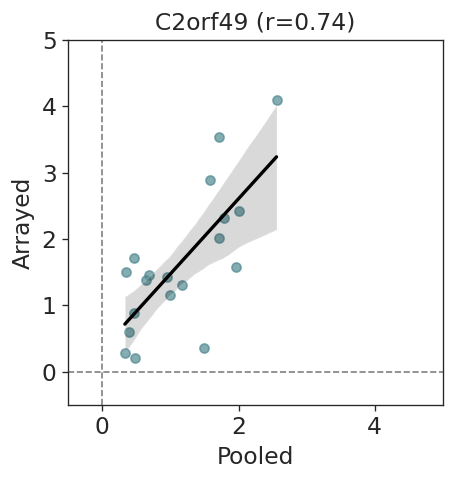

In [7]:
pert = 'C2orf49'
pert2= 'C2ORF49'
df = iN_DEGs_sig[pert][['variable','log_fc']]
print (df.shape)
df.head(2)

df = df.merge(cluster_de_genes[pert2][['names','logfoldchanges']], 'left', left_on='variable', right_on='names')
print (df.shape)
df.head(2)

r, p = stats.pearsonr(df['log_fc'],df['logfoldchanges'])
                      
print (r, p)

sns.regplot(data=df,x='log_fc',y='logfoldchanges',
            scatter_kws={'color': '#508991', 's': 30, 'alpha': 0.7},
            line_kws={'color': 'black', 'lw': 2}
           )
plt.ylim((-0.5,5))
plt.xlim((-0.5,5))
# Add horizontal and vertical lines at zero
plt.axhline(0, color='grey', lw=1, ls='--')
plt.axvline(0, color='grey', lw=1, ls='--')
plt.xlabel('Pooled')
plt.ylabel('Arrayed')
plt.title(f"{pert} (r={r:.2})")
plt.savefig(os.path.join(figsave,f'correlation_iN_{pert}.pdf'), bbox_inches='tight', dpi=300)
plt.show()

(114, 2)
(114, 4)
0.8363841904172055 5.111022605035549e-31


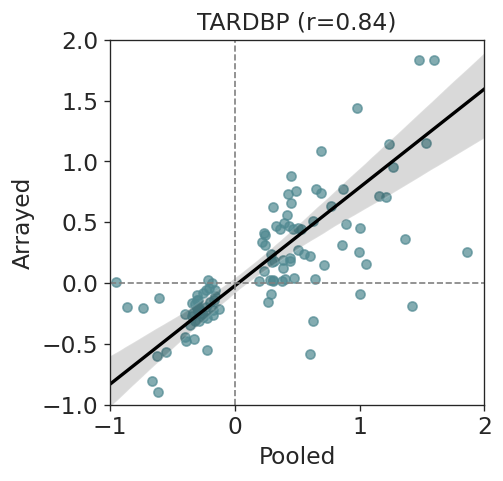

In [8]:
pert = 'TARDBP'
df = iN_DEGs_sig[pert][['variable','log_fc']]
print (df.shape)
df.head(2)

df = df.merge(cluster_de_genes[pert][['names','logfoldchanges']], 'left', left_on='variable', right_on='names')
print (df.shape)
df.head(2)

r, p = stats.pearsonr(df['log_fc'],df['logfoldchanges'])
                      
print (r, p)

sns.regplot(data=df,x='log_fc',y='logfoldchanges',
            scatter_kws={'color': '#508991', 's': 30, 'alpha': 0.7},
            line_kws={'color': 'black', 'lw': 2}
           )
plt.ylim((-1,2))
plt.xlim((-1,2))
# Add horizontal and vertical lines at zero
plt.axhline(0, color='grey', lw=1, ls='--')
plt.axvline(0, color='grey', lw=1, ls='--')
plt.xlabel('Pooled')
plt.ylabel('Arrayed')
plt.title(f"{pert} (r={r:.2})")
plt.savefig(os.path.join(figsave,f'correlation_iN_{pert}.pdf'), bbox_inches='tight', dpi=300)


### iAstrocytes

In [8]:
adata_a = sc.read('../array_scRNAseq/adatas/iAstrocytes.h5ad')
adata_a

AnnData object with n_obs × n_vars = 38512 × 2000
    obs: 'Sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'Cell_type', 'S_score', 'G2M_score', 'phase', 'cell_cycle_diff', 'leiden_0.5', 'score_iA_up_CCDC6', 'score_iA_up_STK11', 'score_iA_down_CCDC6', 'score_iA_down_STK11'
    var: 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: 'Sample_colors', 'hvg', 'leiden_0.5', 'leiden_0.5_colors', 'log1p', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'log1p', 'raw'
    obsp: 'connectivities', 'distances'

In [9]:
adata_n.X.max(), adata_a.X.max()

(np.float32(5.5658684), np.float32(6.8757153))

In [10]:
import pickle
with open('../array_scRNAseq/wilcoxon_arrayed_iAstrocytes.pkl', "rb") as f:
    cluster_de_genes = pickle.load(f)

In [11]:
import pickle
with open("/lustre/scratch126/cellgen/lotfollahi/so21/neuroID/DEGs/pyDESeq2/iA_DEGs_sig.pkl", "rb") as f:
    iA_DEGs_sig = pickle.load(f)

In [12]:
from scipy import stats
import seaborn as sns
sns.set_style('ticks')

CCDC6
(2766, 2)
(2766, 4)
0.8587229260461625 0.0


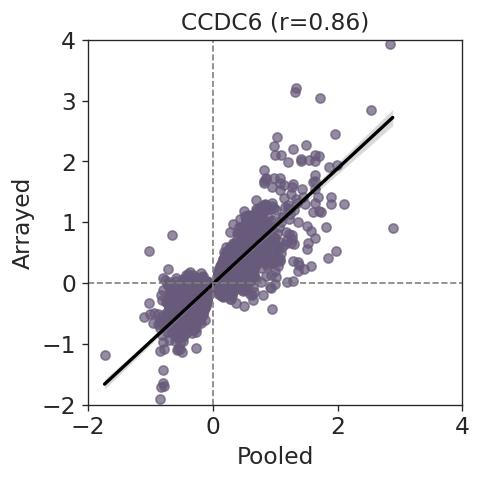

STK11
(581, 2)
(581, 4)
0.6932728097649612 2.041439930147008e-84


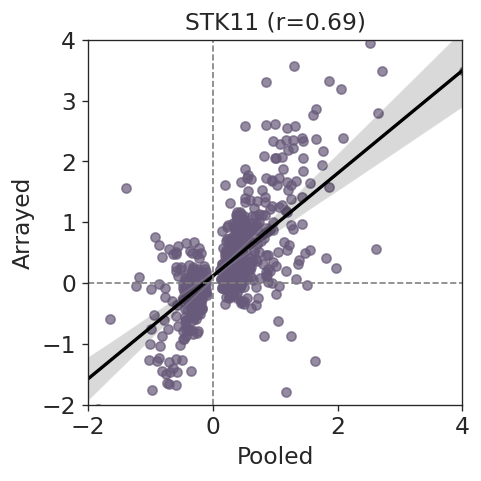

In [13]:
for i in ['CCDC6','STK11']:
    
    pert = i
    print (pert)

    df = iA_DEGs_sig[pert][['variable','log_fc']]
    print (df.shape)
    df.head(2)

    df = df.merge(cluster_de_genes[pert][['names','logfoldchanges']], 'left', left_on='variable', right_on='names')
    print (df.shape)
    df.head(2)

    r, p = stats.pearsonr(df['log_fc'],df['logfoldchanges'])

    print (r, p)

    sns.regplot(data=df,x='log_fc',y='logfoldchanges',
                scatter_kws={'color': '#685a7a', 's': 30, 'alpha': 0.7},
                line_kws={'color': 'black', 'lw': 2}
               )
    plt.ylim((-2,4))
    plt.xlim((-2,4))
    plt.axhline(0, color='grey', lw=1, ls='--')
    plt.axvline(0, color='grey', lw=1, ls='--')
    plt.xlabel('Pooled')
    plt.ylabel('Arrayed')
    plt.title(f"{pert} (r={r:.2})")
    plt.savefig(os.path.join(figsave,f'correlation_iA_{pert}.pdf'), bbox_inches='tight', dpi=300)
    plt.show()


### cell cycle

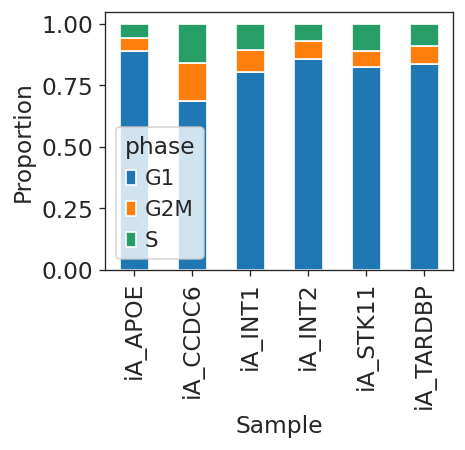

In [14]:
table = (
    adata_a.obs
    .groupby("Sample")["phase"]
    .value_counts(normalize=True)
    .unstack()
)

table.plot.bar(stacked=True)

plt.ylabel("Proportion")
plt.xlabel("Sample")
plt.tight_layout()
plt.show()

In [15]:
table.to_csv('cellCycle_iAstrocytes_arrayed.csv')

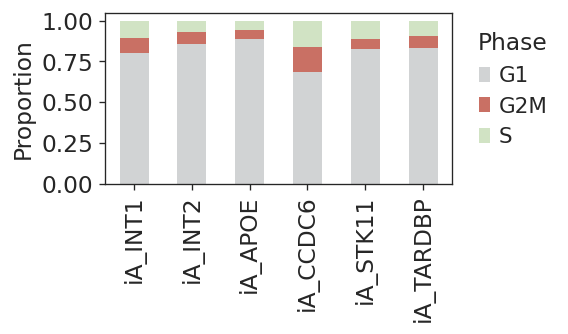

In [16]:
fig, ax = plt.subplots(figsize=(5, 3))

order = ['iA_INT1','iA_INT2','iA_APOE','iA_CCDC6','iA_STK11','iA_TARDBP']
table = table.loc[order]

table.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    edgecolor="none",      # remove white lines
    linewidth=0,
    color=['#d1d3d4','#c97064','#d1e3c4'],       # try different palettes
)

ax.set_ylabel("Proportion")
ax.set_xlabel("")
ax.legend(
    title="Phase",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False,
)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])

plt.tight_layout()
plt.savefig(os.path.join(figsave,f'iA_array_cellCyle.pdf'), bbox_inches='tight', dpi=300)
plt.show()

In [17]:
order = ['iA_INT1','iA_INT2','iA_CCDC6']
table = table.loc[order]
table

phase,G1,G2M,S
Sample,,,
iA_INT1,0.804598,0.091268,0.104134
iA_INT2,0.859315,0.069379,0.071306
iA_CCDC6,0.685425,0.156508,0.158067


In [18]:
[i.replace('iA_','') for i in table.index]

['INT1', 'INT2', 'CCDC6']

In [19]:
table.to_csv('cellCycle_iAstrocytes_arrayed.csv')

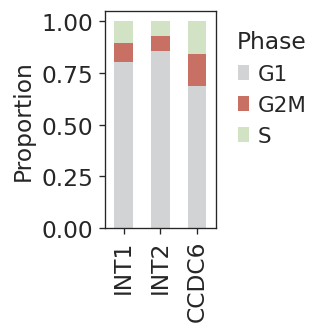

In [20]:
fig, ax = plt.subplots(figsize=(3, 3))

order = ['iA_INT1','iA_INT2','iA_CCDC6']
table = table.loc[order]
table.index = [i.replace('iA_','') for i in table.index]

table.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    edgecolor="none",      # remove white lines
    linewidth=0,
    color=['#d1d3d4','#c97064','#d1e3c4'],       # try different palettes
)

ax.set_ylabel("Proportion")
ax.set_xlabel("")
ax.legend(
    title="Phase",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False,
)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])

plt.tight_layout()
plt.savefig(os.path.join(figsave,f'iA_array_cellCyle2.pdf'), bbox_inches='tight', dpi=300)
plt.show()

In [21]:
adata_a2 = sc.read('../adatas/iAstrocytes_SCREEN1_filtered.h5ad')
adata_a2

AnnData object with n_obs × n_vars = 195306 × 36601
    obs: 'target_gene', 'guide_vector', 'sequencing_batch'

In [22]:
adata_a2 = adata_a2[adata_a2.obs.target_gene.isin(['CCDC6','INT','APOE','STK11','TARDBP'])].copy()
adata_a2.obs.target_gene.value_counts()

target_gene
CCDC6     12351
INT        6111
APOE       1570
STK11      1090
TARDBP      218
Name: count, dtype: int64

In [23]:
adata_a2.X.max()

np.float32(5787.0)

In [24]:
sc.pp.normalize_total(adata_a2, target_sum=1e4, inplace=True)
sc.pp.log1p(adata_a2)

In [25]:
# Cell cycle scoring
cc = pd.read_csv('/nfs/team361/so21/genesets/Tirosh2016_cc_genes.csv')
g1s = list(cc['G1/S'].dropna())
g2m = list(cc['G2/M'].dropna())
sc.tl.score_genes_cell_cycle(adata_a2, s_genes=g1s, g2m_genes=g2m)
adata_a2.obs["cell_cycle_diff"] = adata_a2.obs["S_score"] - adata_a2.obs["G2M_score"]

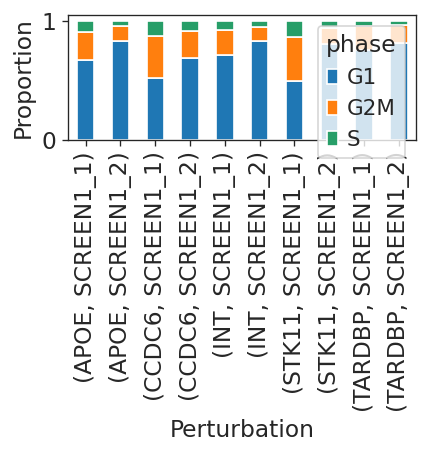

In [27]:
table = (
    adata_a2.obs
    .groupby(["target_gene","sequencing_batch"])["phase"]
    .value_counts(normalize=True)
    .unstack()
)

table.plot.bar(stacked=True)

plt.ylabel("Proportion")
plt.xlabel("Perturbation")
plt.tight_layout()
plt.show()

In [28]:
table.to_csv('cellCycle_iAstrocytes_pooled.csv')

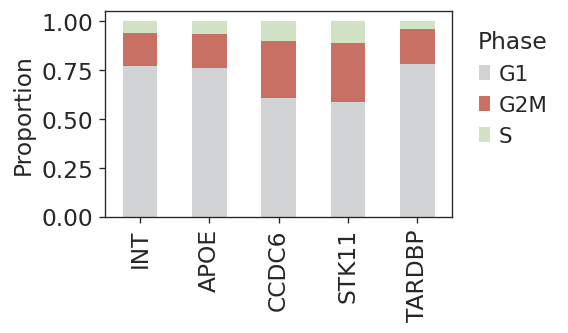

In [27]:
fig, ax = plt.subplots(figsize=(5, 3))

order = ['INT','APOE','CCDC6','STK11','TARDBP']
table = table.loc[order]

table.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    edgecolor="none",      # remove white lines
    linewidth=0,
    color=['#d1d3d4','#c97064','#d1e3c4'],       # try different palettes
)

ax.set_ylabel("Proportion")
ax.set_xlabel("")
ax.legend(
    title="Phase",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False,
)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])

plt.tight_layout()
plt.savefig(os.path.join(figsave,f'iA_pooled_cellCyle.pdf'), bbox_inches='tight', dpi=300)
plt.show()

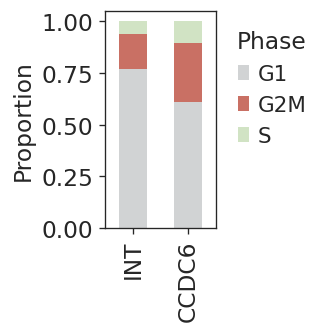

In [28]:
fig, ax = plt.subplots(figsize=(3, 3))

order = ['INT','CCDC6']
table = table.loc[order]

table.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    edgecolor="none",      # remove white lines
    linewidth=0,
    color=['#d1d3d4','#c97064','#d1e3c4'],       # try different palettes
)

ax.set_ylabel("Proportion")
ax.set_xlabel("")
ax.legend(
    title="Phase",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False,
)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])

plt.tight_layout()
plt.savefig(os.path.join(figsave,f'iA_pooled_cellCyle2.pdf'), bbox_inches='tight', dpi=300)
plt.show()

### iNeuron C2orf49 scores only

In [5]:
adata = sc.read('../array_scRNAseq/adatas/counts.h5ad')
adata

AnnData object with n_obs × n_vars = 81540 × 36601
    obs: 'Sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'Cell_type'

In [6]:
adata.obs.Sample.value_counts()

Sample
iA_STK11      11438
iN_STK11       8395
iA_CCDC6       6415
iN_CCDC6       6208
iN_C2ORF49     6066
iN_TARDBP      6013
iA_INT1        5829
iN_INT1        5775
iN_GPATCH8     5450
iA_TARDBP      5416
iN_INT2        5121
iA_APOE        4744
iA_INT2        4670
Name: count, dtype: int64

adata.X shape: (16962, 2000)
adata.raw.X shape: (16962, 26080)


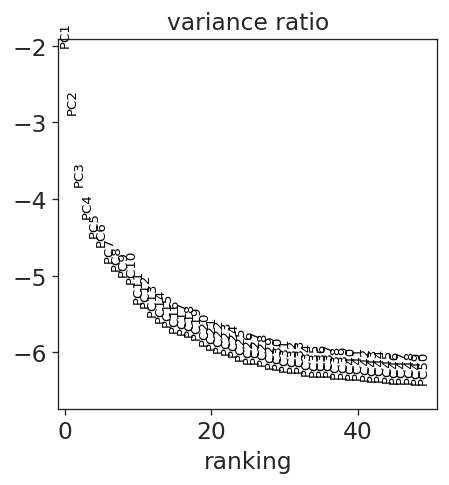

/software/cellgen/team233/so21/envs/scanpy/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [7]:
### remove genes
sc.pp.filter_genes(adata, min_cells=30)
adata.X.shape
adata = adata[adata.obs.Cell_type=='iNeurons'].copy()
adata.X.shape
adata = adata[adata.obs.Sample.isin(['iN_INT1','iN_INT2','iN_C2ORF49'])].copy()
adata.X.shape
adata.layers["raw"] = adata.X.copy() # preserve counts 
sc.pp.normalize_total(adata, target_sum=1e4, inplace=True)
sc.pp.log1p(adata)
adata.layers["log1p"] = adata.X.copy()
adata.raw = adata # keep normalised log1p as raw
# Cell cycle scoring
cc = pd.read_csv('/nfs/team361/so21/genesets/Tirosh2016_cc_genes.csv')
g1s = list(cc['G1/S'].dropna())
g2m = list(cc['G2/M'].dropna())
sc.tl.score_genes_cell_cycle(adata, s_genes=g1s, g2m_genes=g2m)
adata.obs["cell_cycle_diff"] = adata.obs["S_score"] - adata.obs["G2M_score"]
sc.pp.highly_variable_genes(
    adata,
    subset=True,
    layer="raw",
    flavor="seurat_v3",
    n_top_genes=2000,
    span=0.3,
    min_disp=0.5,
    min_mean=0.0125,
    max_mean=3,
    batch_key='Sample'
)
print(f"adata.X shape: {adata.X.shape}")
print(f"adata.raw.X shape: {adata.raw.X.shape}")
sc.tl.pca(adata)
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=20,)
sc.tl.umap(adata)

In [8]:
adata.obs['Perturbation'] = adata.obs['Sample'].str.replace('iN_','')
adata.obs['Perturbation'] = adata.obs['Perturbation'].replace({'INT1':'INT',
                                                             'INT2':'INT'
                                                            })

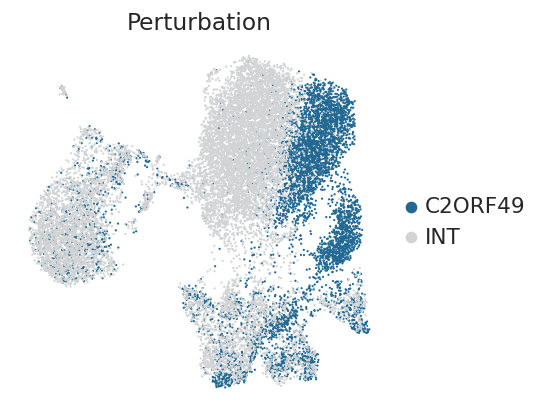

In [9]:
pals = ['#216893','#d1d3d4']
sc.pl.umap(adata, color='Perturbation', palette=pals, frameon=False,
           save='_iN_array_C2orf49only.pdf',)

In [10]:
### GPATCH8, STK11, 2/3 DEGs respectively
iN_DEGs_sig = {k:v for k,v in iN_DEGs_sig.items() if k in ['C2orf49']}

iN_DEGs_sig_up = {}
iN_DEGs_sig_down = {}
for key in iN_DEGs_sig:
    iN_DEGs_sig[key] = iN_DEGs_sig[key].sort_values('log_fc', ascending=False)
    iN_DEGs_sig_up[key] = iN_DEGs_sig[key][iN_DEGs_sig[key]['log_fc']>0.5]['variable'].to_list()
    iN_DEGs_sig_down[key] = iN_DEGs_sig[key][iN_DEGs_sig[key]['log_fc']<-0.5]['variable'].to_list()
    print (key, len(iN_DEGs_sig_up[key]), len(iN_DEGs_sig_down[key]))
    
for k in iN_DEGs_sig_up:
    sc.tl.score_genes(adata, iN_DEGs_sig_up[k], score_name=f"score_iN_up_{k}", use_raw=True)
#for k in ['TARDBP']:
#    sc.tl.score_genes(adata, iN_DEGs_sig_down[k], score_name=f"score_iN_down_{k}", use_raw=True)

C2orf49 13 0


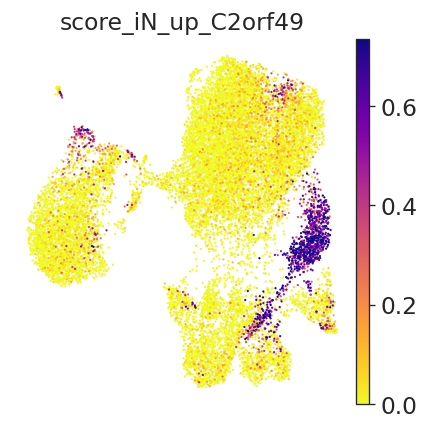

In [12]:
sc.pl.umap(adata, color=['score_iN_up_C2orf49'], vmin=0, vmax='p99', cmap='plasma_r', frameon=False,
           save='_iN_array_C2orf49only_scores.pdf')

In [12]:
adata.write('../array_scRNAseq/adatas/iNeurons_C2ORF49.h5ad')

### iAstrocytes CCDC6 scores only

In [13]:
adata = sc.read('../array_scRNAseq/adatas/counts.h5ad')
adata

AnnData object with n_obs × n_vars = 81540 × 36601
    obs: 'Sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'Cell_type'

adata.X shape: (16914, 2000)
adata.raw.X shape: (16914, 26080)


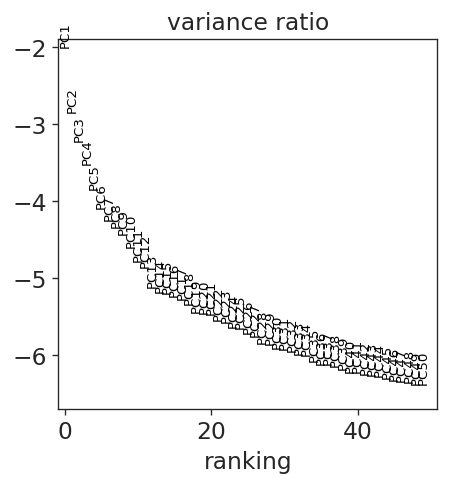

In [14]:
### remove genes
sc.pp.filter_genes(adata, min_cells=30)
adata.X.shape
adata = adata[adata.obs.Cell_type=='iAstrocytes'].copy()
adata.X.shape
adata = adata[adata.obs.Sample.isin(['iA_INT1','iA_INT2','iA_CCDC6'])].copy()
adata.X.shape
adata.layers["raw"] = adata.X.copy() # preserve counts 
sc.pp.normalize_total(adata, target_sum=1e4, inplace=True)
sc.pp.log1p(adata)
adata.layers["log1p"] = adata.X.copy()
adata.raw = adata # keep normalised log1p as raw
# Cell cycle scoring
cc = pd.read_csv('/nfs/team361/so21/genesets/Tirosh2016_cc_genes.csv')
g1s = list(cc['G1/S'].dropna())
g2m = list(cc['G2/M'].dropna())
sc.tl.score_genes_cell_cycle(adata, s_genes=g1s, g2m_genes=g2m)
adata.obs["cell_cycle_diff"] = adata.obs["S_score"] - adata.obs["G2M_score"]
sc.pp.highly_variable_genes(
    adata,
    subset=True,
    layer="raw",
    flavor="seurat_v3",
    n_top_genes=2000,
    span=0.3,
    min_disp=0.5,
    min_mean=0.0125,
    max_mean=3,
    batch_key='Sample'
)
print(f"adata.X shape: {adata.X.shape}")
print(f"adata.raw.X shape: {adata.raw.X.shape}")
sc.tl.pca(adata)
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=20,)
sc.tl.umap(adata)

In [15]:
adata.obs['Perturbation'] = adata.obs['Sample'].str.replace('iA_','')
adata.obs['Perturbation'] = adata.obs['Perturbation'].replace({'INT1':'INT',
                                                             'INT2':'INT'
                                                            })

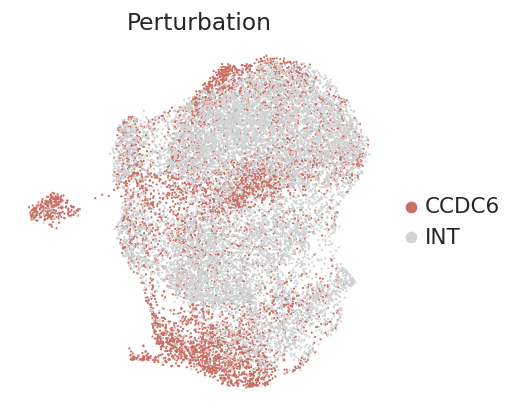

In [16]:
pals = ['#c97064','#d1d3d4']
sc.pl.umap(adata, color='Perturbation', palette=pals, frameon=False,
           save='_iA_array_CCDC6only.pdf',)

In [17]:
### GPATCH8, STK11, 2/3 DEGs respectively
iA_DEGs_sig = {k:v for k,v in iA_DEGs_sig.items() if k in ['CCDC6']}

iA_DEGs_sig_up = {}
iA_DEGs_sig_down = {}
for key in iA_DEGs_sig:
    iA_DEGs_sig[key] = iA_DEGs_sig[key].sort_values('log_fc', ascending=False)
    iA_DEGs_sig_up[key] = iA_DEGs_sig[key][iA_DEGs_sig[key]['log_fc']>0.5]['variable'].to_list()
    iA_DEGs_sig_down[key] = iA_DEGs_sig[key][iA_DEGs_sig[key]['log_fc']<-0.5]['variable'].to_list()
    print (key, len(iA_DEGs_sig_up[key]), len(iA_DEGs_sig_down[key]))
    
for k in iA_DEGs_sig_up:
    sc.tl.score_genes(adata, iA_DEGs_sig_up[k], score_name=f"score_iA_up_{k}", use_raw=True)
#for k in ['TARDBP']:
#    sc.tl.score_genes(adata, iA_DEGs_sig_down[k], score_name=f"score_iN_down_{k}", use_raw=True)

CCDC6 445 139


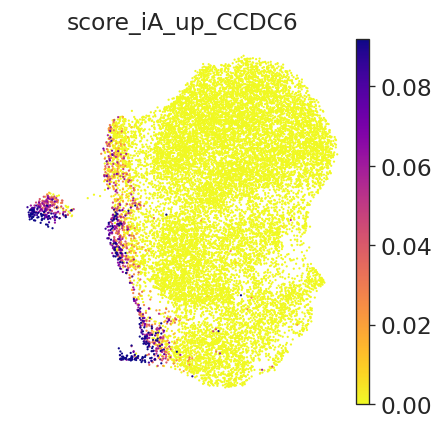

In [18]:
sc.pl.umap(adata, color=['score_iA_up_CCDC6'], vmin=0, vmax='p99', cmap='plasma_r', frameon=False,
           save='_iA_array_CCDC6only_scores.pdf')

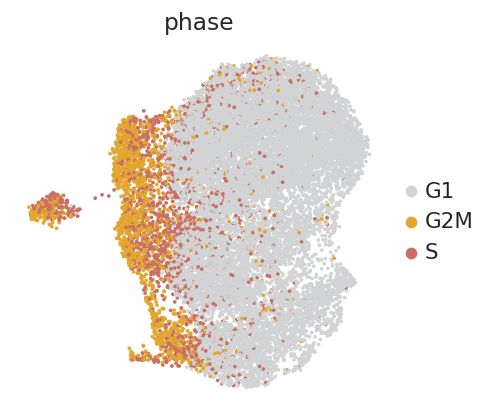

In [19]:
sc.pl.umap(adata, color=['phase'], frameon=False,palette=['#d1d3d4','#e3a72f','#c97064'],
           save='_iA_array_CCDC6only_phase.pdf', size=20)

In [20]:
adata.write('../array_scRNAseq/adatas/iAstrocytes_CCDC6.h5ad')

### scores

In [14]:
adata_a.X.max(), adata_n.X.max()

NameError: name 'adata_a' is not defined

In [33]:
### APOE, TARDBP1 0/1 DEGs respectively
iA_DEGs_sig = {k:v for k,v in iA_DEGs_sig.items() if k in ['CCDC6','STK11']}

iA_DEGs_sig_up = {}
iA_DEGs_sig_down = {}
for key in iA_DEGs_sig:
    iA_DEGs_sig[key] = iA_DEGs_sig[key].sort_values('log_fc', ascending=False)
    iA_DEGs_sig_up[key] = iA_DEGs_sig[key][iA_DEGs_sig[key]['log_fc']>0.5]['variable'].to_list()
    iA_DEGs_sig_down[key] = iA_DEGs_sig[key][iA_DEGs_sig[key]['log_fc']<-0.5]['variable'].to_list()
    print (key, len(iA_DEGs_sig_up[key]), len(iA_DEGs_sig_down[key]))

CCDC6 445 139
STK11 174 52


In [35]:
for k in iA_DEGs_sig_up:
    sc.tl.score_genes(adata_a, iA_DEGs_sig_up[k], score_name=f"score_iA_up_{k}", use_raw=True)
for k in iA_DEGs_sig_down:
    sc.tl.score_genes(adata_a, iA_DEGs_sig_down[k], score_name=f"score_iA_down_{k}", use_raw=True)

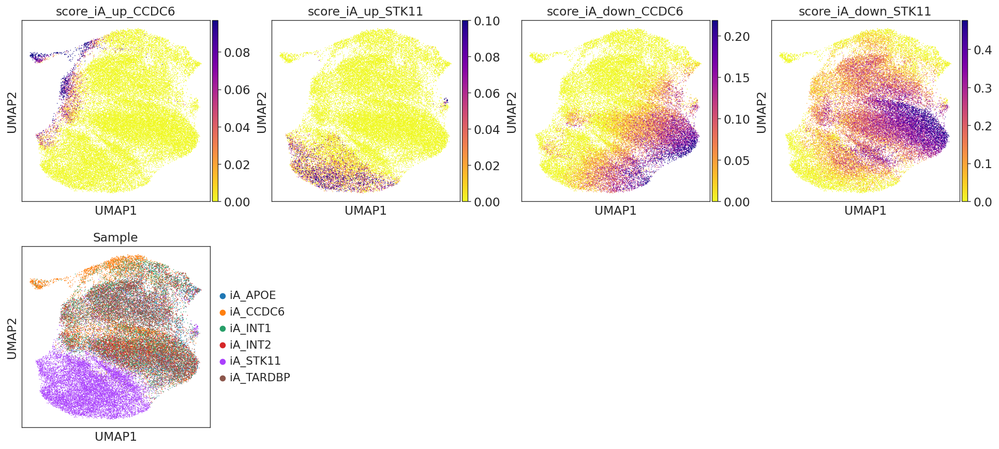

In [37]:
to_plot = list(adata_a.obs.columns[adata_a.obs.columns.str.startswith('score_')])
sc.pl.umap(adata_a, color=to_plot + ['Sample'], vmin=0, vmax='p99', cmap='plasma_r')

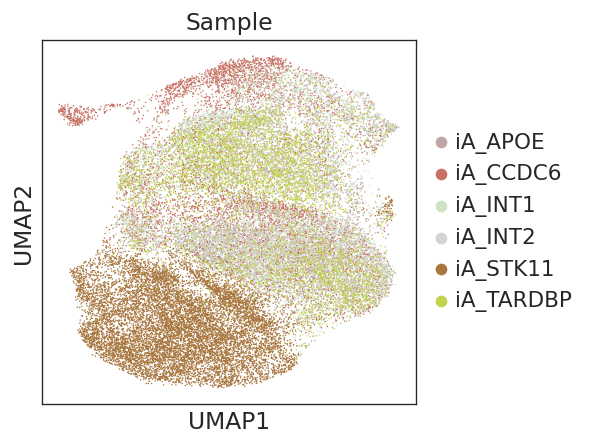

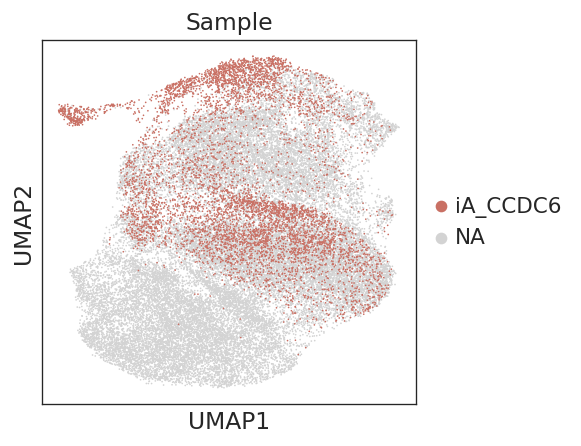

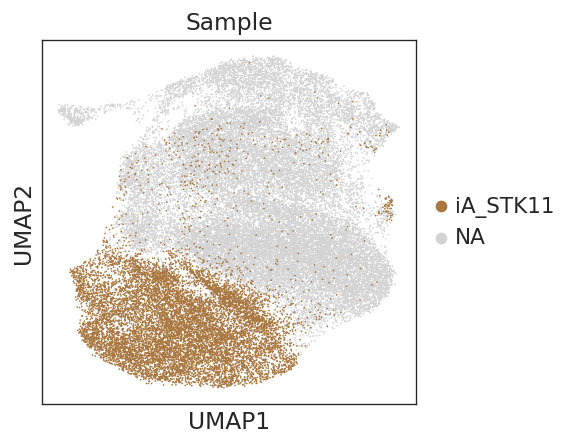

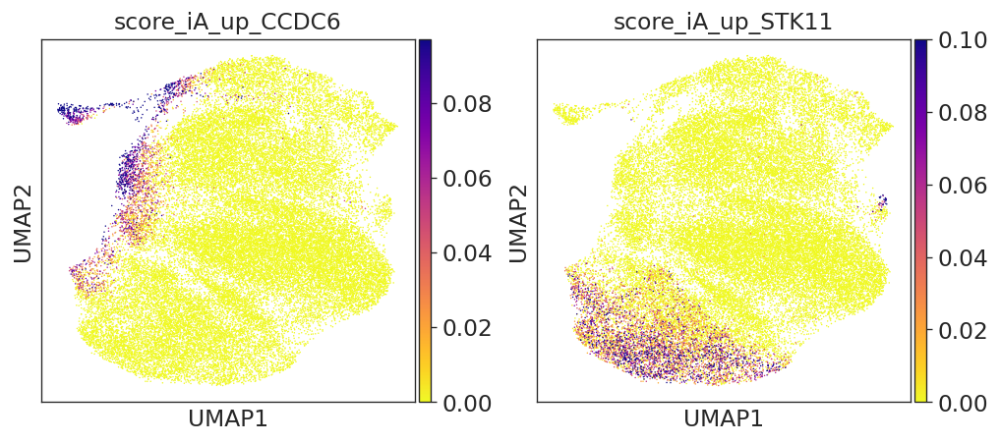

In [46]:
pals = ['#bfa5a4','#c97064','#d1e3c4','#d1d3d4','#a8763e','#c3d24f',]
sc.pl.umap(adata_a, color=['Sample'], palette=pals, save='_iA_array_sample.pdf')
sc.pl.umap(adata_a, color=['Sample'], palette=pals, save='_iA_array_sample_CCDC6.pdf', groups='iA_CCDC6',size=4)
sc.pl.umap(adata_a, color=['Sample'], palette=pals, save='_iA_array_sample_STK11.pdf', groups='iA_STK11',size=4)

sc.pl.umap(adata_a, color=['score_iA_up_CCDC6','score_iA_up_STK11'], vmin=0, vmax='p99', cmap='plasma_r', save='_iA_array_scores.pdf')

In [49]:
### GPATCH8, STK11, 2/3 DEGs respectively
iN_DEGs_sig = {k:v for k,v in iN_DEGs_sig.items() if k in ['C2orf49','TARDBP']}

iN_DEGs_sig_up = {}
iN_DEGs_sig_down = {}
for key in iN_DEGs_sig:
    iN_DEGs_sig[key] = iN_DEGs_sig[key].sort_values('log_fc', ascending=False)
    iN_DEGs_sig_up[key] = iN_DEGs_sig[key][iN_DEGs_sig[key]['log_fc']>0.5]['variable'].to_list()
    iN_DEGs_sig_down[key] = iN_DEGs_sig[key][iN_DEGs_sig[key]['log_fc']<-0.5]['variable'].to_list()
    print (key, len(iN_DEGs_sig_up[key]), len(iN_DEGs_sig_down[key]))
    
for k in iN_DEGs_sig_up:
    sc.tl.score_genes(adata_n, iN_DEGs_sig_up[k], score_name=f"score_iN_up_{k}", use_raw=True)
for k in ['TARDBP']:
    sc.tl.score_genes(adata_n, iN_DEGs_sig_down[k], score_name=f"score_iN_down_{k}", use_raw=True)

C2orf49 13 0
TARDBP 36 10


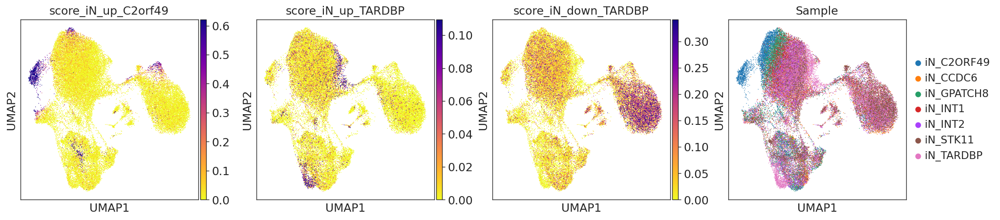

In [50]:
to_plot = list(adata_n.obs.columns[adata_n.obs.columns.str.startswith('score_')])
sc.pl.umap(adata_n, color=to_plot + ['Sample'], vmin=0, vmax='p99', cmap='plasma_r')

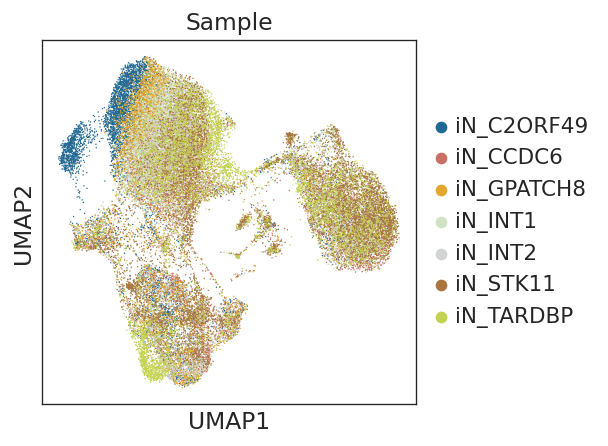

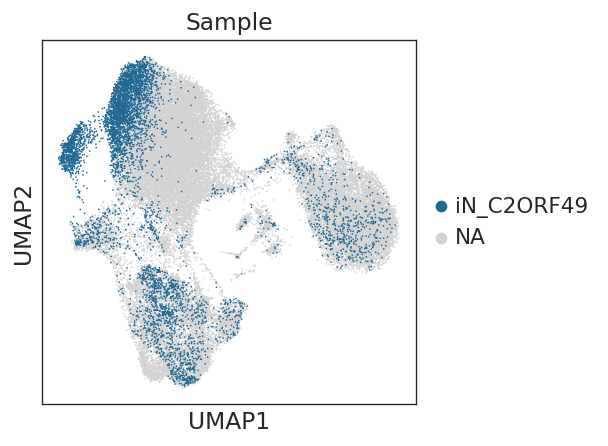

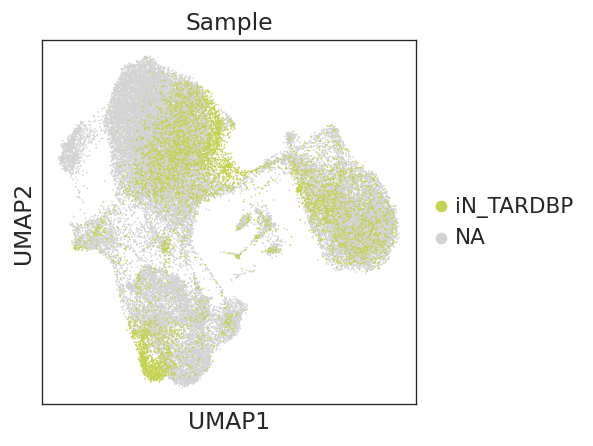

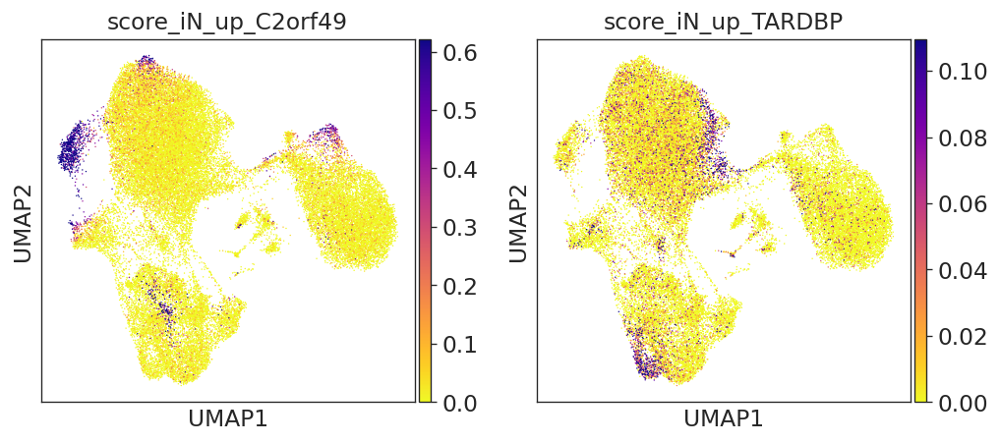

In [53]:
pals = ['#216893','#c97064','#e3a72f','#d1e3c4','#d1d3d4','#a8763e','#c3d24f',]

sc.pl.umap(adata_n, color=['Sample'], palette=pals, save='_iN_array_sample.pdf')
sc.pl.umap(adata_n, color=['Sample'], palette=pals, save='_iN_array_sample_C2ORF49.pdf', groups='iN_C2ORF49',size=4)
sc.pl.umap(adata_n, color=['Sample'], palette=pals, save='_iN_array_sample_TARDBP.pdf', groups='iN_TARDBP',size=4)

sc.pl.umap(adata_n, color=['score_iN_up_C2orf49','score_iN_up_TARDBP'], vmin=0, vmax='p99', cmap='plasma_r', save='_iN_array_scores.pdf')

### string - CCDC6

In [5]:
import pickle
with open('../array_scRNAseq/wilcoxon_arrayed_iAstrocytes.pkl', "rb") as f:
    cluster_de_genes = pickle.load(f)
    
genes = cluster_de_genes['CCDC6'][(cluster_de_genes['CCDC6']['logfoldchanges']>0.5) &
                                  (cluster_de_genes['CCDC6']['pct_nz_group']>0.1) &
                                  (cluster_de_genes['CCDC6']['pvals_adj']<0.05)
                                 ]['names'].to_list()
len(genes)

416

In [6]:
genes = cluster_de_genes['CCDC6'][(cluster_de_genes['CCDC6']['logfoldchanges']>0.5) &
                                  (cluster_de_genes['CCDC6']['pct_nz_group']>0.1) &
                                  (cluster_de_genes['CCDC6']['pvals_adj']<0.05)
                                 ]['names'].to_list()
len(genes)

416

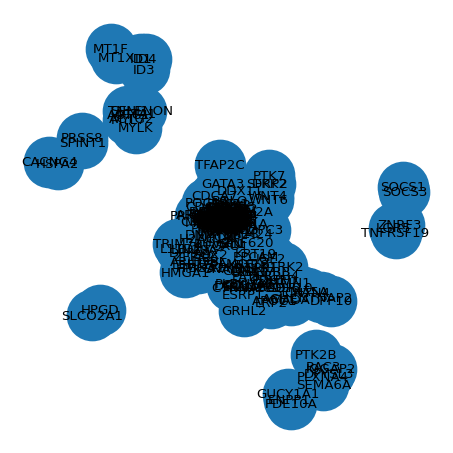

In [7]:
import requests
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

species = 9606  # human

url = "https://string-db.org/api/tsv/network"
params = {
    "identifiers": "%0d".join(genes),
    "species": species,
    "required_score": 700,
    "network_type": "functional"
}

r = requests.post(url, data=params)
rows = [line.split("\t") for line in r.text.strip().split("\n")]
df = pd.DataFrame(rows[1:], columns=rows[0])

G = nx.from_pandas_edgelist(
    df,
    source="preferredName_A",
    target="preferredName_B",
    edge_attr="score"
)

pos = nx.spring_layout(G, seed=1)

plt.figure(figsize=(4, 4))
nx.draw_networkx_edges(G, pos, alpha=0.35, width=1)
nx.draw_networkx_nodes(G, pos, node_size=900)
nx.draw_networkx_labels(G, pos, font_size=8)

plt.axis("off")
plt.tight_layout()
plt.savefig("string_network.svg", format="svg")
plt.savefig("string_network.pdf")

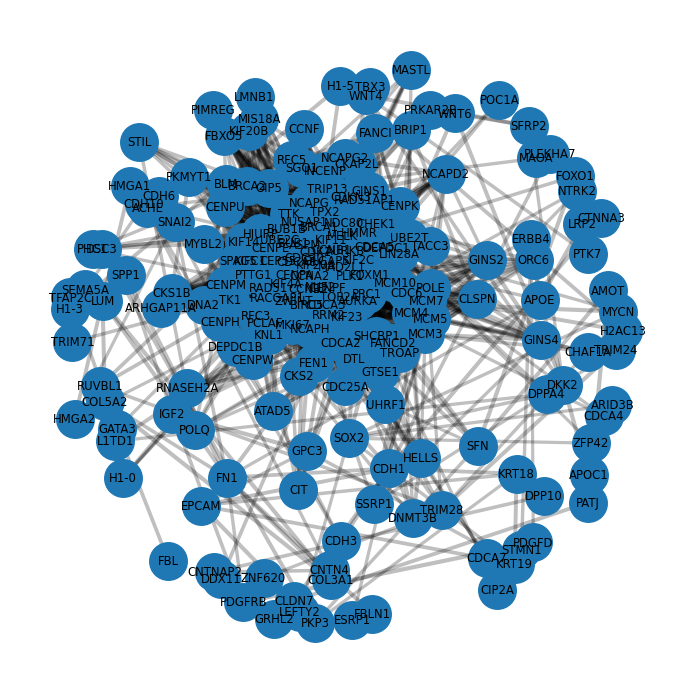

In [8]:
import io
import requests
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

genes = sorted(set(genes))

url = "https://string-db.org/api/tsv/network"
params = {
    "identifiers": "\r".join(genes),
    "species": 9606,
    "required_score": 700,
    "network_type": "functional",
    "caller_identity": "ccdc6_arrayed_iAstrocytes"
}

r = requests.post(url, data=params, timeout=60)
r.raise_for_status()

if not r.text.strip():
    raise ValueError("STRING returned no interactions.")

df = pd.read_csv(io.StringIO(r.text), sep="\t")
df["score"] = pd.to_numeric(df["score"], errors="coerce")

G = nx.from_pandas_edgelist(
    df,
    source="preferredName_A",
    target="preferredName_B",
    edge_attr=True
)

# Optional: keep largest connected component
G = G.subgraph(max(nx.connected_components(G), key=len)).copy()

pos = nx.spring_layout(
    G,
    seed=1,
    weight="score",
    k=0.8
)

plt.figure(figsize=(6, 6))
nx.draw_networkx_edges(
    G, pos,
    alpha=0.25,
    width=[0.5 + 2 * G[u][v]["score"] for u, v in G.edges()]
)
nx.draw_networkx_nodes(G, pos, node_size=500)
nx.draw_networkx_labels(G, pos, font_size=7)

plt.axis("off")
plt.tight_layout()
plt.savefig("CCDC6_STRING_network.svg", format="svg")
plt.savefig("CCDC6_STRING_network.pdf")

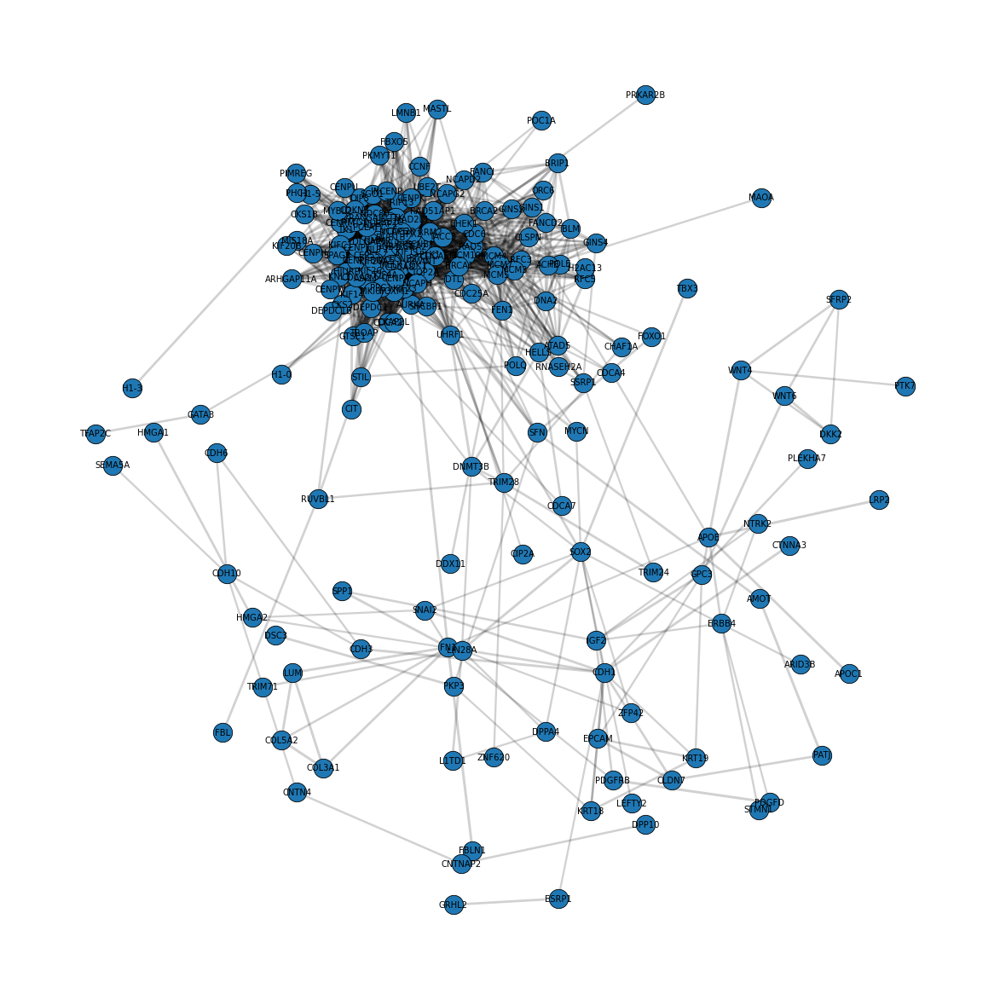

In [9]:
# 2. Remove tiny disconnected components
components = [G.subgraph(c).copy() for c in nx.connected_components(G)]
G = nx.compose_all([c for c in components if c.number_of_nodes() >= 5])

# 3. Use a more spacious layout
pos = nx.spring_layout(
    G,
    seed=1,
    k=1.8,          # larger = more spread out
    iterations=300,
    weight="score"
)

# 4. Draw with smaller nodes and lighter edges
plt.figure(figsize=(10, 10))

nx.draw_networkx_edges(
    G, pos,
    alpha=0.18,
    width=[0.3 + 1.5 * G[u][v]["score"] for u, v in G.edges()]
)

nx.draw_networkx_nodes(
    G, pos,
    node_size=180,
    linewidths=0.5,
    edgecolors="black"
)

# 5. Draw labels separately
nx.draw_networkx_labels(
    G, pos,
    font_size=6,
    font_weight="regular"
)

plt.axis("off")
plt.tight_layout()
plt.savefig("CCDC6_STRING_network_readable.svg")
plt.savefig("CCDC6_STRING_network_readable.pdf")

### STRING C2ORF49

In [10]:
import pickle
import requests
with open('../array_scRNAseq/wilcoxon_arrayed_iNeurons.pkl', "rb") as f:
    cluster_de_genes = pickle.load(f)

In [11]:
genes = cluster_de_genes['C2ORF49'][(cluster_de_genes['C2ORF49']['logfoldchanges']>0.5) & #up-regulated only
                                  (cluster_de_genes['C2ORF49']['pct_nz_group']>0.1) & #only expressed in at least 10% of cells
                                  (cluster_de_genes['C2ORF49']['pvals_adj']<0.05) #significant genes only
                                 ]['names'].to_list()
len(genes)

120

In [12]:
species = 9606

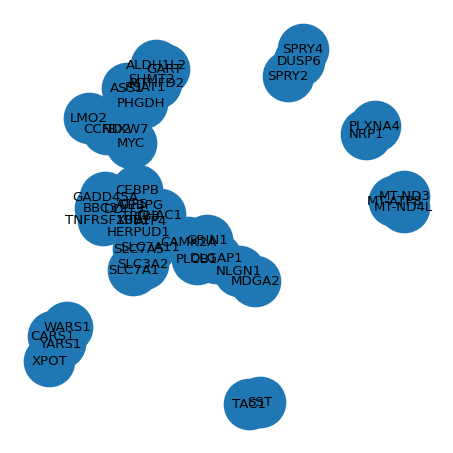

In [13]:
url = "https://string-db.org/api/tsv/network"
params = {
    "identifiers": "%0d".join(genes),
    "species": species,
    "required_score": 700,
    "network_type": "functional"
}

r = requests.post(url, data=params)
rows = [line.split("\t") for line in r.text.strip().split("\n")]
df = pd.DataFrame(rows[1:], columns=rows[0])

G = nx.from_pandas_edgelist(
    df,
    source="preferredName_A",
    target="preferredName_B",
    edge_attr="score"
)

pos = nx.spring_layout(G, seed=1)

plt.figure(figsize=(4, 4))
nx.draw_networkx_edges(G, pos, alpha=0.35, width=1)
nx.draw_networkx_nodes(G, pos, node_size=900)
nx.draw_networkx_labels(G, pos, font_size=8)

plt.axis("off")
plt.tight_layout()
plt.savefig("string_network.svg", format="svg")
plt.savefig("string_network.pdf")

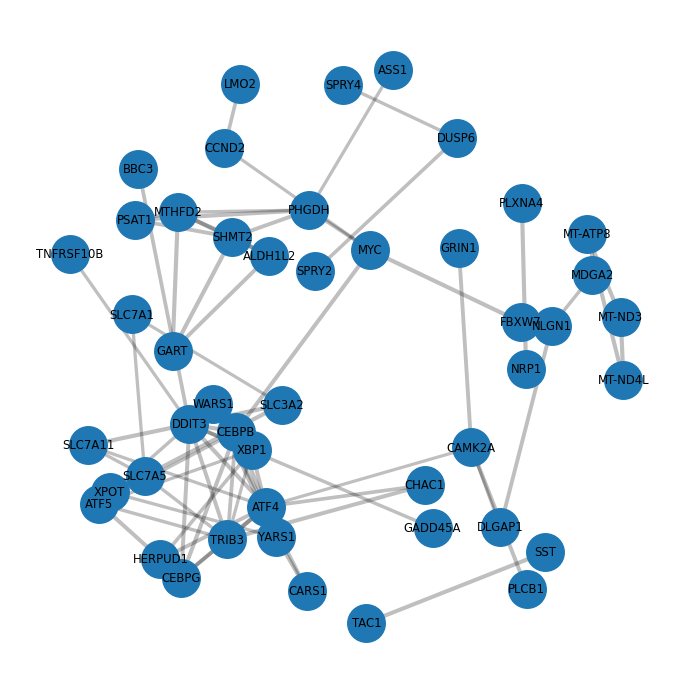

In [14]:
import io
import requests
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

genes = sorted(set(genes))

url = "https://string-db.org/api/tsv/network"
params = {
    "identifiers": "\r".join(genes),
    "species": 9606,
    "required_score": 700,
    "network_type": "functional",
    "caller_identity": "ccdc6_arrayed_iAstrocytes"
}

r = requests.post(url, data=params, timeout=60)
r.raise_for_status()

if not r.text.strip():
    raise ValueError("STRING returned no interactions.")

df = pd.read_csv(io.StringIO(r.text), sep="\t")
df["score"] = pd.to_numeric(df["score"], errors="coerce")

G = nx.from_pandas_edgelist(
    df,
    source="preferredName_A",
    target="preferredName_B",
    edge_attr=True
)

# Optional: keep largest connected component
#G = G.subgraph(max(nx.connected_components(G), key=len)).copy()

pos = nx.spring_layout(
    G,
    seed=1,
    weight="score",
    k=0.8
)

plt.figure(figsize=(6, 6))
nx.draw_networkx_edges(
    G, pos,
    alpha=0.25,
    width=[0.5 + 2 * G[u][v]["score"] for u, v in G.edges()]
)
nx.draw_networkx_nodes(G, pos, node_size=500)
nx.draw_networkx_labels(G, pos, font_size=7)

plt.axis("off")
plt.tight_layout()
plt.savefig("figures/STRING_network_C2orf49.pdf")

In [15]:
import gseapy as gp

enr_reactome = gp.enrichr(
    gene_list=genes,
    gene_sets=[
        #"GO_Biological_Process_2023",
        "Reactome_Pathways_2024"
    ],
    organism="Human",
    outdir=None,
)

enr_reactome.results.to_csv('stringGO_C2orf49_up_reactome.csv')
#enr_reactome.results.head(20)

import gseapy as gp

enr = gp.enrichr(
    gene_list=genes,
    gene_sets=[
        "GO_Biological_Process_2023",
        #"Reactome_Pathways_2024"
    ],
    organism="Human",
    outdir=None,
)

enr.results.to_csv('stringGO_C2orf49_up_GO.csv')
#enr.results.head(20)

In [16]:
go_dict = (
    enr.results
    .assign(Term=lambda x: x["Term"].str.strip())
    .set_index("Term")["Genes"]
    .str.split(";")
    .to_dict()
)

res_dict = (
    enr_reactome.results
    .assign(Term=lambda x: x["Term"].str.strip())
    .set_index("Term")["Genes"]
    .str.split(";")
    .to_dict()
)

go_terms = [
    "Negative Regulation Of MAPK Cascade (GO:0043409)",
    "Response To Endoplasmic Reticulum Stress (GO:0034976)",
    #"Intrinsic Apoptotic Signaling Pathway In Response To Endoplasmic Reticulum Stress (GO:0070059)",
    "Amino Acid Transport (GO:0006865)",
]

reactome_terms = [
    #"Response of EIF2AK1 (HRI) to Heme Deficiency",
    #"ATF4 Activates Genes in Response to Endoplasmic Reticulum Stress",
    #"PERK Regulates Gene Expression",
    #"Unfolded Protein Response (UPR)",
    #"Amino Acid Transport Across the Plasma Membrane",
]

In [17]:
reactome_terms = {k:v for k,v in res_dict.items() if k in reactome_terms}  
go_terms = {k:v for k,v in go_dict.items() if k in go_terms} 
terms = go_terms | reactome_terms


In [18]:
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import networkx as nx

def plot_pathway_network(
    G,
    pos,
    pathway_genes,
    multiple_colour="gold",
    other_colour="lightgrey",
    cmap="tab10",
    savepath=None,
):

    # one colour per pathway
    colours = plt.get_cmap(cmap).colors
    pathway_colours = {
        pathway: mcolors.to_hex(colours[i % len(colours)])
        for i, pathway in enumerate(pathway_genes)
    }

    pathway_genes = {k: set(v) for k, v in pathway_genes.items()}

    node_colours = []
    node_edges = []

    for node in G.nodes():

        matches = [
            pathway
            for pathway, genes in pathway_genes.items()
            if node in genes
        ]

        if len(matches) > 1:
            node_colours.append(multiple_colour)
            node_edges.append("black")
        elif len(matches) == 1:
            node_colours.append(pathway_colours[matches[0]])
            node_edges.append("black")
        else:
            node_colours.append(other_colour)
            node_edges.append("grey")

    plt.figure(figsize=(6, 6))

    nx.draw_networkx_edges(
        G,
        pos,
        alpha=0.25,
        width=[0.5 + 2 * G[u][v]["score"] for u, v in G.edges()],
    )

    nx.draw_networkx_nodes(
        G,
        pos,
        node_size=500,
        node_color=node_colours,
        edgecolors=node_edges,
        linewidths=0.7,
    )

    nx.draw_networkx_labels(G, pos, font_size=7)

    handles = [
        Line2D(
            [0], [0],
            marker="o",
            color="w",
            markerfacecolor=colour,
            markeredgecolor="black",
            markersize=9,
            label=pathway,
        )
        for pathway, colour in pathway_colours.items()
    ]

    handles += [
        Line2D([0], [0], marker="o", color="w",
               markerfacecolor=multiple_colour,
               markeredgecolor="black",
               label="Multiple pathways",
               markersize=9),

        Line2D([0], [0], marker="o", color="w",
               markerfacecolor=other_colour,
               markeredgecolor="grey",
               label="Other genes",
               markersize=9),
    ]

    plt.legend(
        handles=handles,
        frameon=False,
        fontsize=7,
        loc="center left",
        bbox_to_anchor=(1, 0.5),
    )

    plt.axis("off")
    plt.tight_layout()

    if savepath:
        plt.savefig(savepath, bbox_inches="tight")

    plt.show()

In [29]:
def plot_pathway_network(
    G, pos, pathway_genes,
    multiple_colour="#685a7a",
    other_colour="lightgrey",
    cmap=['#80cdc1','#dfc17c','#c97064','#d1d3d4'] , #"tab10",
    savepath=None,
    figsize=(8, 6)
):

    if isinstance(cmap, str):
        colours = plt.get_cmap(cmap).colors
    else:
        colours = cmap
    pathway_colours = {
        pathway: colours[i % len(colours)]
        for i, pathway in enumerate(pathway_genes)
    }

    pathway_genes = {k: set(v) for k, v in pathway_genes.items()}

    node_colours, node_edges = [], []

    for node in G.nodes():
        matches = [p for p, genes in pathway_genes.items() if node in genes]

        if len(matches) > 1:
            node_colours.append(multiple_colour)
            node_edges.append("black")
        elif len(matches) == 1:
            node_colours.append(pathway_colours[matches[0]])
            node_edges.append("black")
        else:
            node_colours.append(other_colour)
            node_edges.append("grey")

    fig, ax = plt.subplots(figsize=figsize)

    nx.draw_networkx_edges(
        G, pos, ax=ax,
        alpha=0.25,
        width=[0.5 + 2 * G[u][v]["score"] for u, v in G.edges()]
    )

    nx.draw_networkx_nodes(
        G, pos, ax=ax,
        node_size=500,
        node_color=node_colours,
        edgecolors=node_edges,
        linewidths=0.7
    )

    nx.draw_networkx_labels(G, pos, ax=ax, font_size=7)

    handles = [
        Line2D([0], [0], marker="o", color="w",
               markerfacecolor=colour,
               markeredgecolor="black",
               label=pathway,
               markersize=9)
        for pathway, colour in pathway_colours.items()
    ]

    handles += [
        Line2D([0], [0], marker="o", color="w",
               markerfacecolor=multiple_colour,
               markeredgecolor="black",
               label="Multiple pathways",
               markersize=9),
        Line2D([0], [0], marker="o", color="w",
               markerfacecolor=other_colour,
               markeredgecolor="grey",
               label="Other genes",
               markersize=9),
    ]

    ax.legend(
        handles=handles,
        frameon=False,
        fontsize=7,
        loc="center left",
        bbox_to_anchor=(1.02, 0.5)
    )

    ax.set_axis_off()

    if savepath:
        plt.savefig(savepath, bbox_inches="tight",)

    plt.show()

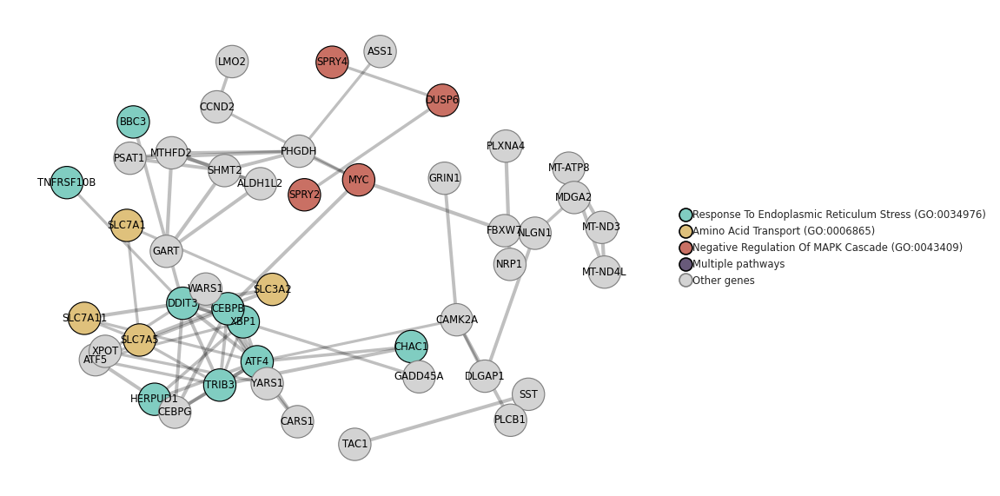

In [30]:
plot_pathway_network(G, pos, terms,
                    savepath='figures/STRING_network_C2orf49.pdf')

In [31]:
genes = cluster_de_genes['C2ORF49'][(cluster_de_genes['C2ORF49']['logfoldchanges']<-0.5) & #up-regulated only
                                  (cluster_de_genes['C2ORF49']['pct_nz_group']>0.1) & #only expressed in at least 10% of cells for up-regulated
                                  (cluster_de_genes['C2ORF49']['pvals_adj']<0.05) #significant genes only
                                 ]['names'].to_list()
len(genes)

101

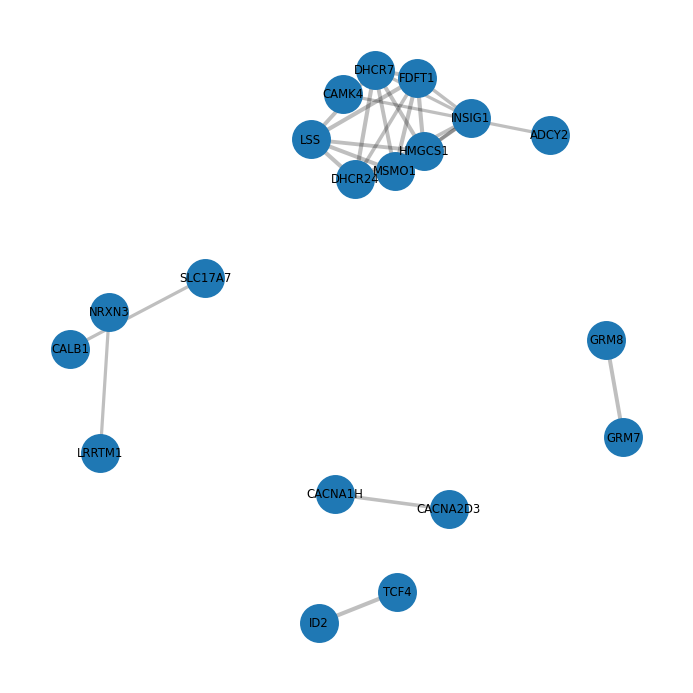

In [32]:
import io
import requests
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

genes = sorted(set(genes))

url = "https://string-db.org/api/tsv/network"
params = {
    "identifiers": "\r".join(genes),
    "species": 9606,
    "required_score": 700,
    "network_type": "functional",
    "caller_identity": "ccdc6_arrayed_iAstrocytes"
}

r = requests.post(url, data=params, timeout=60)
r.raise_for_status()

if not r.text.strip():
    raise ValueError("STRING returned no interactions.")

df = pd.read_csv(io.StringIO(r.text), sep="\t")
df["score"] = pd.to_numeric(df["score"], errors="coerce")

G = nx.from_pandas_edgelist(
    df,
    source="preferredName_A",
    target="preferredName_B",
    edge_attr=True
)

# Optional: keep largest connected component
#G = G.subgraph(max(nx.connected_components(G), key=len)).copy()

pos = nx.spring_layout(
    G,
    seed=1,
    weight="score",
    k=0.8
)

plt.figure(figsize=(6, 6))
nx.draw_networkx_edges(
    G, pos,
    alpha=0.25,
    width=[0.5 + 2 * G[u][v]["score"] for u, v in G.edges()]
)
nx.draw_networkx_nodes(G, pos, node_size=500)
nx.draw_networkx_labels(G, pos, font_size=7)

plt.axis("off")
plt.tight_layout()
plt.savefig("figures/STRING_network_C2orf49_down.pdf")

In [33]:
import gseapy as gp

enr_reactome = gp.enrichr(
    gene_list=genes,
    gene_sets=[
        #"GO_Biological_Process_2023",
        "Reactome_Pathways_2024"
    ],
    organism="Human",
    outdir=None,
)

enr_reactome.results.to_csv('stringGO_C2orf49_down_reactome.csv')
#enr_reactome.results.head(20)

import gseapy as gp

enr = gp.enrichr(
    gene_list=genes,
    gene_sets=[
        "GO_Biological_Process_2023",
        #"Reactome_Pathways_2024"
    ],
    organism="Human",
    outdir=None,
)

enr.results.to_csv('stringGO_C2orf49_down_GO.csv')
#enr.results.head(20)

In [34]:
go_dict = (
    enr.results
    .assign(Term=lambda x: x["Term"].str.strip())
    .set_index("Term")["Genes"]
    .str.split(";")
    .to_dict()
)

res_dict = (
    enr_reactome.results
    .assign(Term=lambda x: x["Term"].str.strip())
    .set_index("Term")["Genes"]
    .str.split(";")
    .to_dict()
)

go_terms = [
    "Cholesterol Biosynthetic Process (GO:0006695)",
    #"Axonogenesis (GO:0007409)",
]

reactome_terms = [
    "Neuronal System"
]

reactome_terms = {k:v for k,v in res_dict.items() if k in reactome_terms}  
go_terms = {k:v for k,v in go_dict.items() if k in go_terms} 
terms = go_terms | reactome_terms

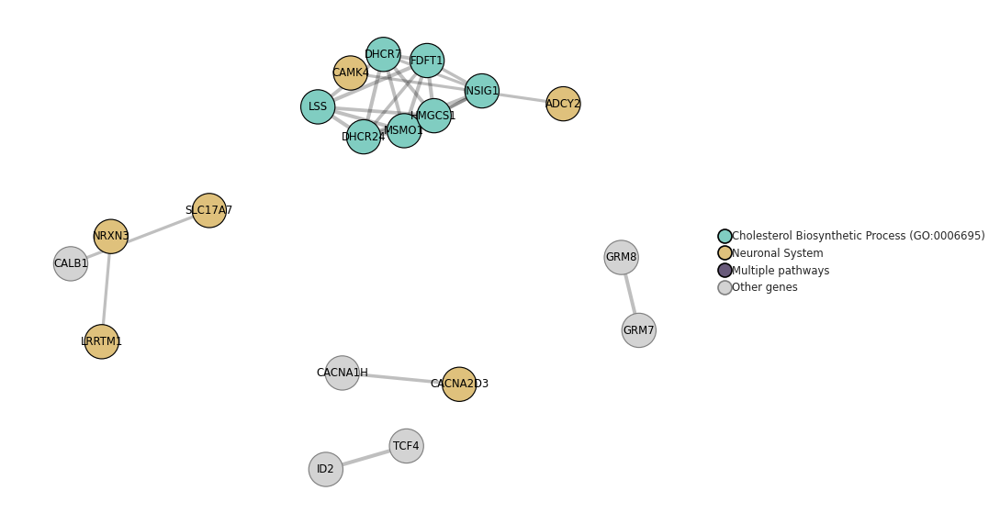

In [35]:
plot_pathway_network(G, pos, terms,
                    savepath='figures/STRING_network_C2orf49_down.pdf')

### CCDC6 STRING

In [36]:
import pickle
with open('../array_scRNAseq/wilcoxon_arrayed_iAstrocytes.pkl', "rb") as f:
    cluster_de_genes = pickle.load(f)

In [37]:
genes = cluster_de_genes['CCDC6'][(cluster_de_genes['CCDC6']['logfoldchanges']<-0.5) & #up-regulated only
                                  (cluster_de_genes['CCDC6']['pct_nz_group']>0.1) & #only expressed in at least 10% of cells for up-regulated
                                  (cluster_de_genes['CCDC6']['pvals_adj']<0.05) #significant genes only
                                 ]['names'].to_list()
len(genes)

229

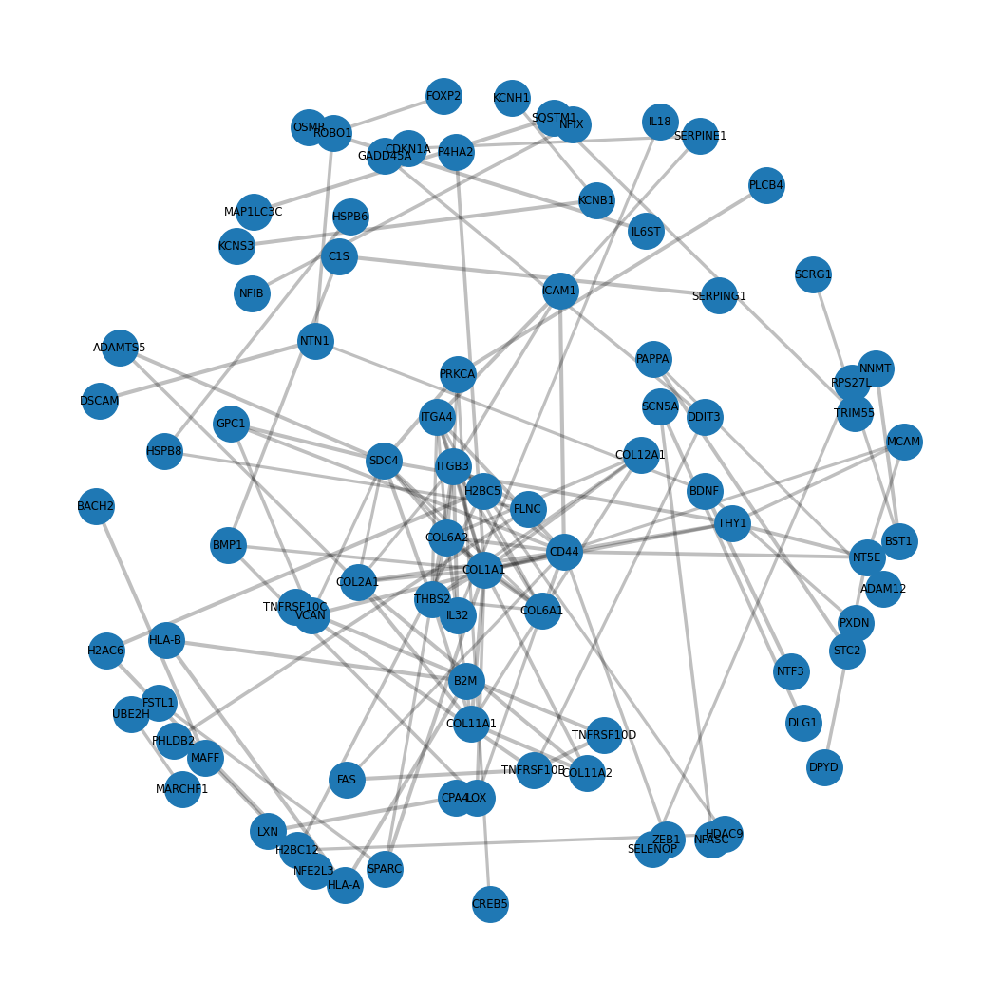

In [38]:
import io
import requests
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

genes = sorted(set(genes))

url = "https://string-db.org/api/tsv/network"
params = {
    "identifiers": "\r".join(genes),
    "species": 9606,
    "required_score": 700,
    "network_type": "functional",
    "caller_identity": "ccdc6_arrayed_iAstrocytes"
}

r = requests.post(url, data=params, timeout=60)
r.raise_for_status()

if not r.text.strip():
    raise ValueError("STRING returned no interactions.")

df = pd.read_csv(io.StringIO(r.text), sep="\t")
df["score"] = pd.to_numeric(df["score"], errors="coerce")

G = nx.from_pandas_edgelist(
    df,
    source="preferredName_A",
    target="preferredName_B",
    edge_attr=True
)

# Optional: keep largest connected component
#G = G.subgraph(max(nx.connected_components(G), key=len)).copy()

pos = nx.spring_layout(
    G,
    seed=1,
    weight="score",
    k=0.8
)

plt.figure(figsize=(9, 9))
nx.draw_networkx_edges(
    G, pos,
    alpha=0.25,
    width=[0.5 + 2 * G[u][v]["score"] for u, v in G.edges()]
)
nx.draw_networkx_nodes(G, pos, node_size=500)
nx.draw_networkx_labels(G, pos, font_size=7)

plt.axis("off")
plt.tight_layout()
plt.savefig("figures/STRING_network_CCDC6_down.pdf")

In [39]:
import gseapy as gp

enr_reactome = gp.enrichr(
    gene_list=genes,
    gene_sets=[
        #"GO_Biological_Process_2023",
        "Reactome_Pathways_2024"
    ],
    organism="Human",
    outdir=None,
)

enr_reactome.results.to_csv('stringGO_CCDC6_down_reactome.csv')
#enr_reactome.results.head(20)

import gseapy as gp

enr = gp.enrichr(
    gene_list=genes,
    gene_sets=[
        "GO_Biological_Process_2023",
        #"Reactome_Pathways_2024"
    ],
    organism="Human",
    outdir=None,
)

enr.results.to_csv('stringGO_CCDC6_down_GO.csv')
#enr.results.head(20)

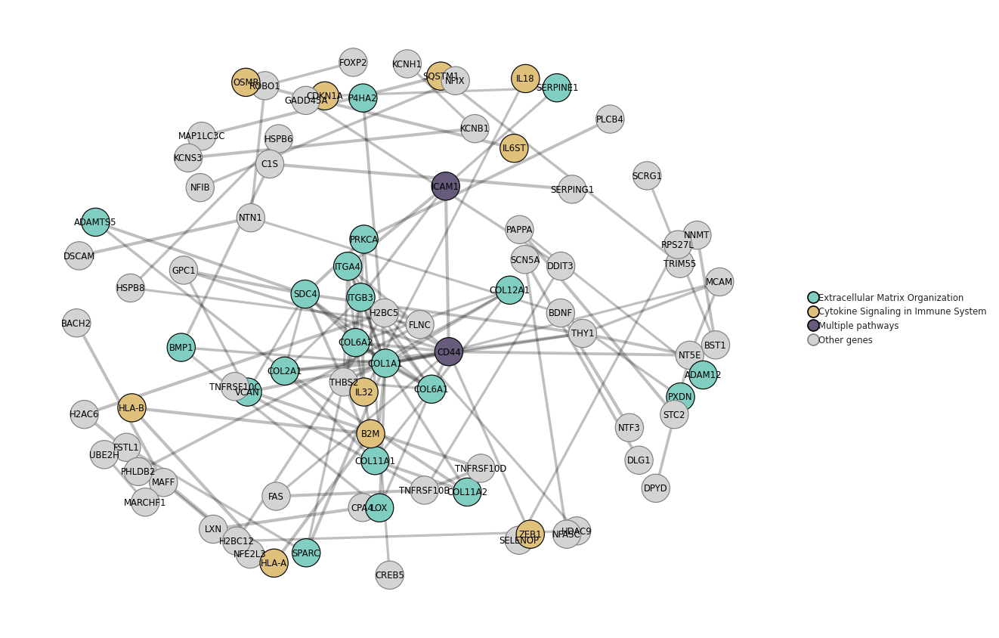

In [40]:
go_dict = (
    enr.results
    .assign(Term=lambda x: x["Term"].str.strip())
    .set_index("Term")["Genes"]
    .str.split(";")
    .to_dict()
)

res_dict = (
    enr_reactome.results
    .assign(Term=lambda x: x["Term"].str.strip())
    .set_index("Term")["Genes"]
    .str.split(";")
    .to_dict()
)

go_terms = [
    #"Positive Regulation Of MAPK Cascade (GO:0043410)"
    #"Axonogenesis (GO:0007409)",
    #'Cytokine-Mediated Signaling Pathway (GO:0019221)'
]

reactome_terms = [
    #"Interferon Gamma Signaling",
    "Extracellular Matrix Organization",
    "Cytokine Signaling in Immune System"
]

reactome_terms = {k:v for k,v in res_dict.items() if k in reactome_terms}  
go_terms = {k:v for k,v in go_dict.items() if k in go_terms} 
terms = go_terms | reactome_terms

plot_pathway_network(G, pos, terms,figsize=(11, 9),
                    savepath='figures/STRING_network_CCDC6_down.pdf')

In [41]:
genes = cluster_de_genes['CCDC6'][(cluster_de_genes['CCDC6']['logfoldchanges']>0.5) & #up-regulated only
                                  (cluster_de_genes['CCDC6']['pct_nz_group']>0.1) & #only expressed in at least 10% of cells
                                  (cluster_de_genes['CCDC6']['pvals_adj']<0.05) #significant genes only
                                 ]['names'].to_list()
len(genes)

416

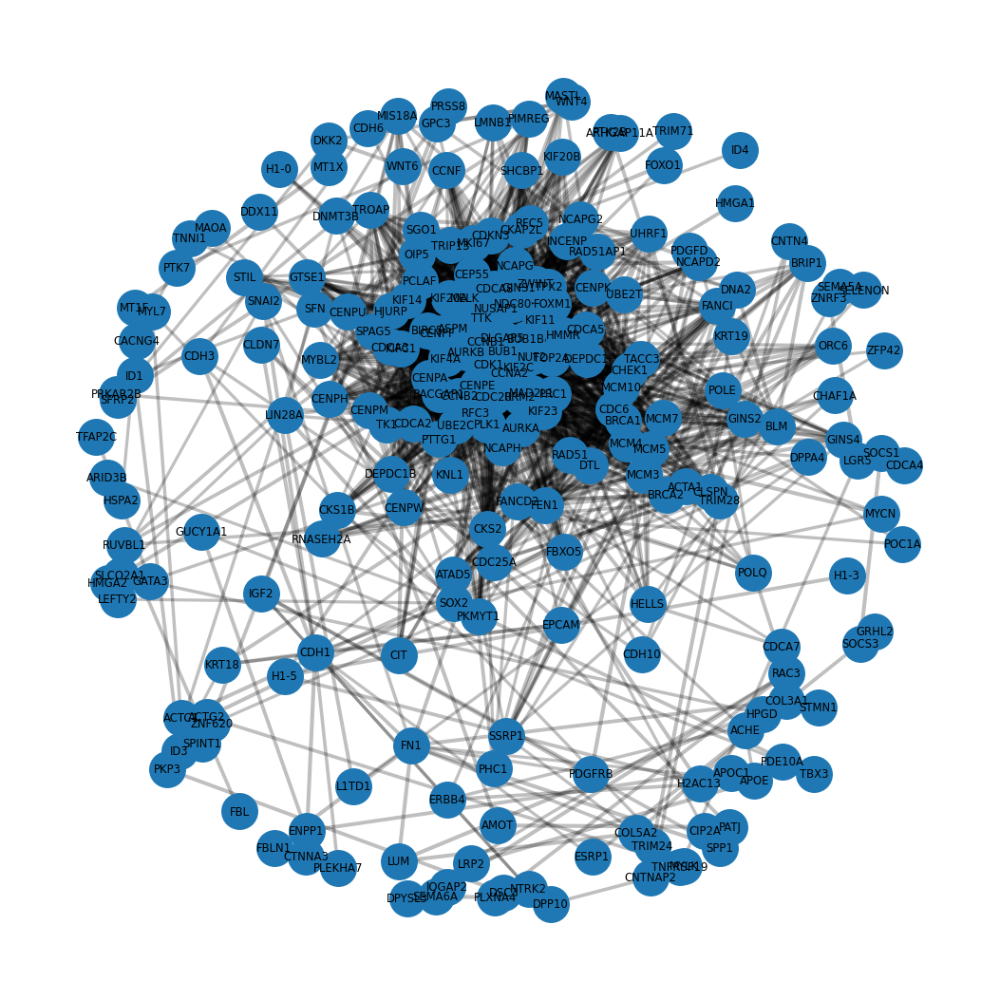

In [42]:
import io
import requests
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

genes = sorted(set(genes))

url = "https://string-db.org/api/tsv/network"
params = {
    "identifiers": "\r".join(genes),
    "species": 9606,
    "required_score": 700,
    "network_type": "functional",
    "caller_identity": "ccdc6_arrayed_iAstrocytes"
}

r = requests.post(url, data=params, timeout=60)
r.raise_for_status()

if not r.text.strip():
    raise ValueError("STRING returned no interactions.")

df = pd.read_csv(io.StringIO(r.text), sep="\t")
df["score"] = pd.to_numeric(df["score"], errors="coerce")

G = nx.from_pandas_edgelist(
    df,
    source="preferredName_A",
    target="preferredName_B",
    edge_attr=True
)

# Optional: keep largest connected component
#G = G.subgraph(max(nx.connected_components(G), key=len)).copy()

pos = nx.spring_layout(
    G,
    seed=1,
    weight="score",
    k=0.8
)

plt.figure(figsize=(9, 9))
nx.draw_networkx_edges(
    G, pos,
    alpha=0.25,
    width=[0.5 + 2 * G[u][v]["score"] for u, v in G.edges()]
)
nx.draw_networkx_nodes(G, pos, node_size=500)
nx.draw_networkx_labels(G, pos, font_size=7)

plt.axis("off")
plt.tight_layout()
plt.savefig("figures/STRING_network_CCDC6_up.pdf")

In [43]:
import gseapy as gp

enr_reactome = gp.enrichr(
    gene_list=genes,
    gene_sets=[
        #"GO_Biological_Process_2023",
        "Reactome_Pathways_2024"
    ],
    organism="Human",
    outdir=None,
)

enr_reactome.results.to_csv('stringGO_CCDC6_up_reactome.csv')
#enr_reactome.results.head(20)

import gseapy as gp

enr = gp.enrichr(
    gene_list=genes,
    gene_sets=[
        "GO_Biological_Process_2023",
        #"Reactome_Pathways_2024"
    ],
    organism="Human",
    outdir=None,
)

enr.results.to_csv('stringGO_CCDC6_up_GO.csv')
#enr.results.head(20)

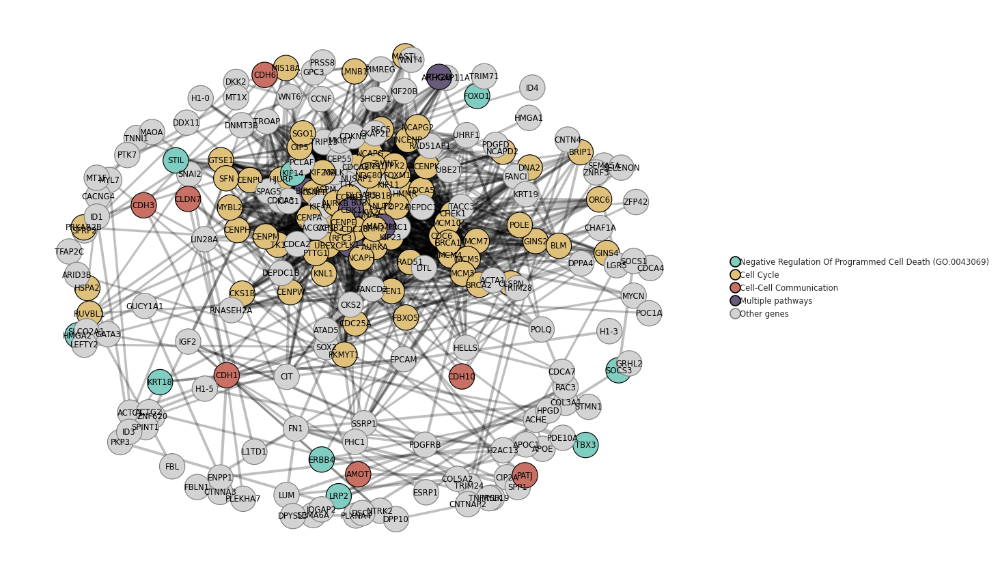

In [44]:
go_dict = (
    enr.results
    .assign(Term=lambda x: x["Term"].str.strip())
    .set_index("Term")["Genes"]
    .str.split(";")
    .to_dict()
)

res_dict = (
    enr_reactome.results
    .assign(Term=lambda x: x["Term"].str.strip())
    .set_index("Term")["Genes"]
    .str.split(";")
    .to_dict()
)

go_terms = [
    #"Mitotic Sister Chromatid Segregation (GO:0000070)",
    #"DNA Replication (GO:0006260)",
    #'Regulation Of Apoptotic Process (GO:0042981)',
    "Negative Regulation Of Programmed Cell Death (GO:0043069)",
]

reactome_terms = [
    "Cell Cycle",
    #'Regulation Of Apoptotic Process (GO:0042981)',
    "Negative Regulation Of Programmed Cell Death (GO:0043069)",
    'Cell-Cell Communication'
    #"Signaling by Rho GTPases",
]

reactome_terms = {k:v for k,v in res_dict.items() if k in reactome_terms}  
go_terms = {k:v for k,v in go_dict.items() if k in go_terms} 
terms = go_terms | reactome_terms

plot_pathway_network(G, pos, terms,figsize=(11, 9),
                    savepath='figures/STRING_network_CCDC6_up.pdf')

# GO figures

In [21]:
CCDC6_GO_up = pd.read_csv('stringGO_CCDC6_up_GO.csv', index_col=0)
CCDC6_GO_up = CCDC6_GO_up[CCDC6_GO_up['Adjusted P-value']<0.05]
CCDC6_GO_up.to_csv('stringGO_CCDC6_up_GO_sig.csv')

In [22]:
CCDC6_GO_down = pd.read_csv('stringGO_CCDC6_down_GO.csv', index_col=0)
CCDC6_GO_down = CCDC6_GO_down[CCDC6_GO_down['Adjusted P-value']<0.05]
CCDC6_GO_down.to_csv('stringGO_CCDC6_down_GO_sig.csv')

In [23]:
CCDC6_reactome_up = pd.read_csv('stringGO_CCDC6_up_reactome.csv', index_col=0)
CCDC6_reactome_up = CCDC6_reactome_up[CCDC6_reactome_up['Adjusted P-value']<0.05]
CCDC6_reactome_up.to_csv('stringGO_CCDC6_up_reactome_sig.csv')

In [24]:
CCDC6_reactome_down = pd.read_csv('stringGO_CCDC6_down_reactome.csv', index_col=0)
CCDC6_reactome_down = CCDC6_reactome_down[CCDC6_reactome_down['Adjusted P-value']<0.05]
CCDC6_reactome_down.to_csv('stringGO_CCDC6_down_reactome_sig.csv')

In [25]:
CCDC6_up = pd.concat([CCDC6_GO_up, CCDC6_reactome_up]).sort_values(by='Combined Score',ascending=False)#.drop(columns='Unnamed: 0')
CCDC6_up.to_csv('stringGO_CCDC6_up_all_sig.csv')

In [26]:
CCDC6_down = pd.concat([CCDC6_GO_down, CCDC6_reactome_down]).sort_values(by='Combined Score',ascending=False)#.drop(columns='Unnamed: 0')
CCDC6_down.to_csv('stringGO_CCDC6_down_all_sig.csv')

In [27]:
down_terms = [
    "Extracellular Matrix Organization",
    "Nervous System Development",
    "Signaling by Receptor Tyrosine Kinases",
    "Positive Regulation Of MAPK Cascade (GO:0043410)",
    "Regulation Of Cell Migration (GO:0030334)",
]

In [28]:
up_terms = [
    "Cell Cycle",
    "DNA-templated DNA Replication (GO:0006261)",
    "RHO GTPase Effectors",
    'Positive Regulation Of Cell Cycle Process (GO:0090068)',
    "Positive Regulation Of MAPK Cascade (GO:0043410)"
]

In [29]:
import textwrap
import seaborn as sns
import matplotlib.pyplot as plt

def plot_enrichment_bar(df, terms, title, savepath=None, figsize=(5, 5), fill_col='#35978f', wrap=35):
    plot_df = df[df["Term"].isin(terms)].copy()
    plot_df["minus_log10_padj"] = -np.log10(plot_df["Adjusted P-value"])
    plot_df["Term_wrapped"] = plot_df["Term"].apply(lambda x: "\n".join(textwrap.wrap(x, wrap)))

    plot_df = plot_df.sort_values("minus_log10_padj", ascending=False)

    fig, ax = plt.subplots(figsize=figsize)

    sns.barplot(
        data=plot_df,
        x="minus_log10_padj",
        y="Term_wrapped",
        ax=ax,
        color=fill_col
    )

    ax.set_xlabel("-log10 adjusted P-value")
    ax.set_ylabel("")
    ax.set_title(title)
    sns.despine(ax=ax)

    plt.subplots_adjust(left=0.5, right=0.9, top=0.9, bottom=0.1)

    if savepath:
        plt.savefig(savepath, dpi=300)

    plt.show()

In [30]:
sns.set_style('ticks')

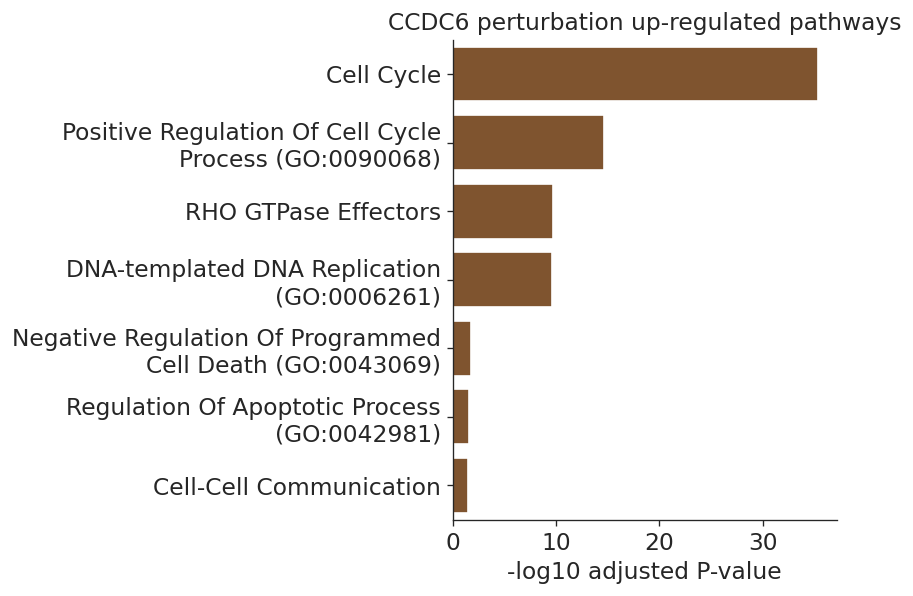

In [31]:
up_terms = [
    "Cell Cycle",
    "DNA-templated DNA Replication (GO:0006261)",
    "RHO GTPase Effectors",
    'Positive Regulation Of Cell Cycle Process (GO:0090068)',
    'Regulation Of Apoptotic Process (GO:0042981)',
    "Negative Regulation Of Programmed Cell Death (GO:0043069)",
    'Cell-Cell Communication'
]

plot_enrichment_bar(df = CCDC6_up, 
                    terms = up_terms,
                    title = 'CCDC6 perturbation up-regulated pathways',
                    savepath = "figures_draft/GO_barplot_CCDC6_up.pdf",
                    figsize=(8,5),
                    fill_col='#8c5322'
                   )

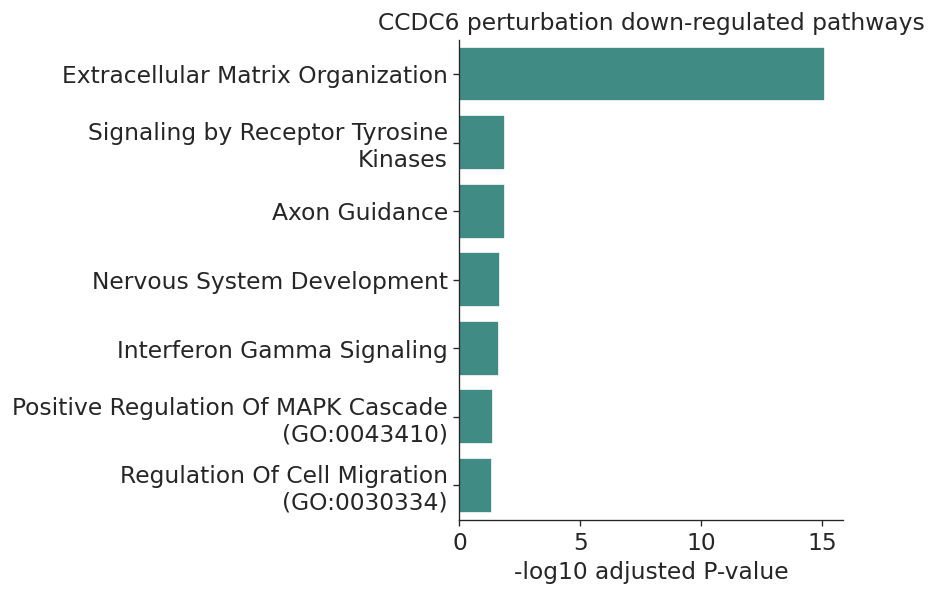

In [32]:
terms = [
    "Extracellular Matrix Organization",
    "Nervous System Development",
    "Axon Guidance",
    "Signaling by Receptor Tyrosine Kinases",
    "Positive Regulation Of MAPK Cascade (GO:0043410)",
    "Regulation Of Cell Migration (GO:0030334)",
    "Interferon Gamma Signaling",
]

plot_enrichment_bar(df = CCDC6_down, 
                    terms = terms,
                    title = 'CCDC6 perturbation down-regulated pathways',
                    savepath = "figures_draft/GO_barplot_CCDC6_down.pdf",
                    figsize=(8,5),
                    fill_col='#35978f'
                   )

### C2ORF49

In [33]:
C2orf49_GO_up = pd.read_csv('stringGO_C2orf49_up_GO.csv', index_col=0)
C2orf49_GO_up = C2orf49_GO_up[C2orf49_GO_up['Adjusted P-value']<0.05]
C2orf49_GO_up.to_csv('stringGO_C2orf49_up_GO_sig.csv')

C2orf49_GO_down = pd.read_csv('stringGO_C2orf49_down_GO.csv', index_col=0)
C2orf49_GO_down = C2orf49_GO_down[C2orf49_GO_down['Adjusted P-value']<0.05]
C2orf49_GO_down.to_csv('stringGO_C2orf49_down_GO_sig.csv')

C2orf49_reactome_up = pd.read_csv('stringGO_C2orf49_up_reactome.csv', index_col=0)
C2orf49_reactome_up = C2orf49_reactome_up[C2orf49_reactome_up['Adjusted P-value']<0.05]
C2orf49_reactome_up.to_csv('stringGO_C2orf49_up_reactome_sig.csv')

C2orf49_reactome_down = pd.read_csv('stringGO_C2orf49_down_reactome.csv', index_col=0)
C2orf49_reactome_down = C2orf49_reactome_down[C2orf49_reactome_down['Adjusted P-value']<0.05]
C2orf49_reactome_down.to_csv('stringGO_C2orf49_down_reactome_sig.csv')

C2orf49_up = pd.concat([C2orf49_GO_up, C2orf49_reactome_up]).sort_values(by='Combined Score',ascending=False)#.drop(columns='Unnamed: 0')
C2orf49_up.to_csv('stringGO_C2orf49_up_all_sig.csv')

C2orf49_down = pd.concat([C2orf49_GO_down, C2orf49_reactome_down]).sort_values(by='Combined Score',ascending=False)#.drop(columns='Unnamed: 0')
C2orf49_down.to_csv('stringGO_C2orf49_down_all_sig.csv')

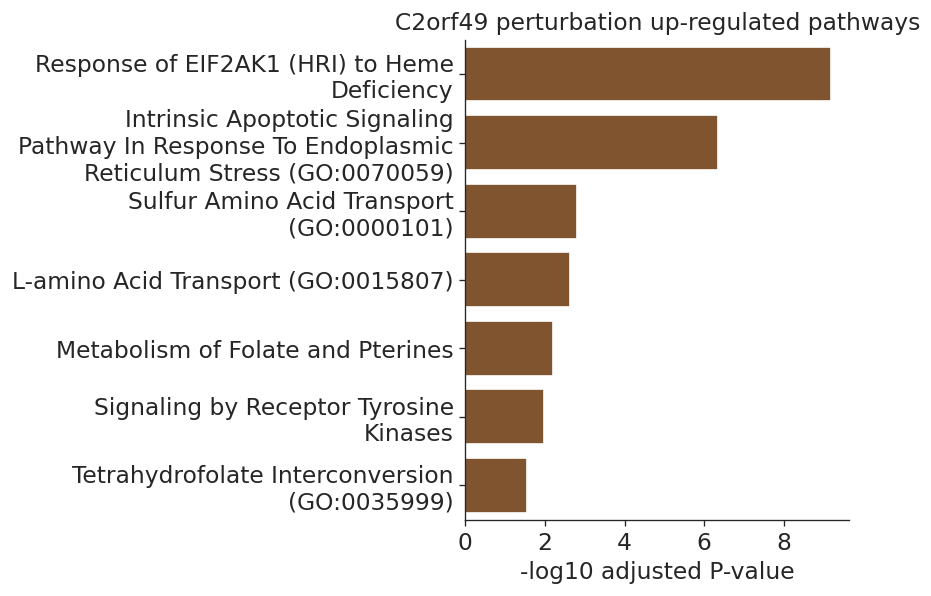

In [34]:
up_terms = [
    "Response of EIF2AK1 (HRI) to Heme Deficiency",
    "Intrinsic Apoptotic Signaling Pathway In Response To Endoplasmic Reticulum Stress (GO:0070059)",
    #"ATF4 Activates Genes in Response to Endoplasmic Reticulum Stress",
    "Sulfur Amino Acid Transport (GO:0000101)",
    "L-amino Acid Transport (GO:0015807)",
    "Metabolism of Folate and Pterines",
    "Tetrahydrofolate Interconversion (GO:0035999)",
    'Signaling by Receptor Tyrosine Kinases'
]

plot_enrichment_bar(df = C2orf49_up, 
                    terms = up_terms,
                    title = 'C2orf49 perturbation up-regulated pathways',
                    savepath = "figures_draft/GO_barplot_C2orf49_up.pdf",
                    figsize=(8,5),
                    fill_col='#8c5322'
                   )

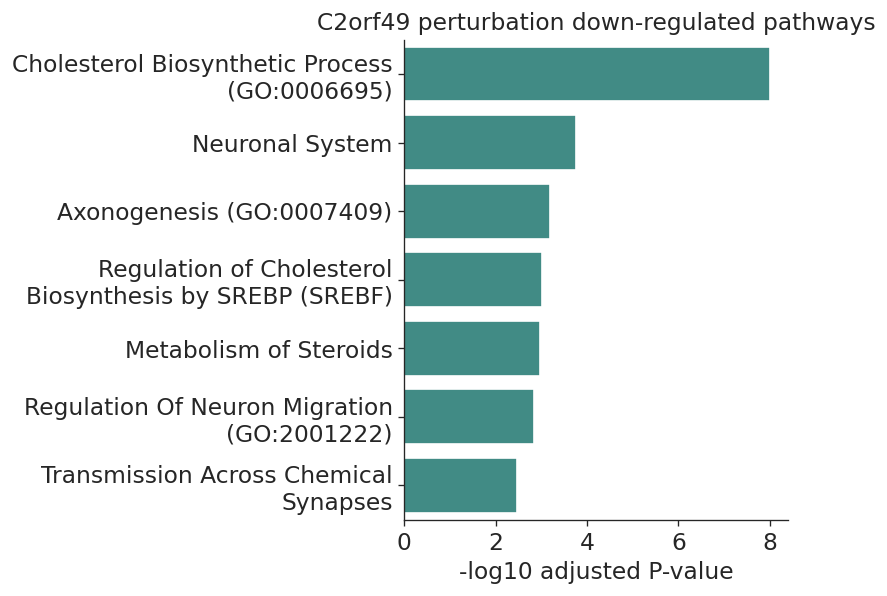

In [35]:
terms = [
    "Cholesterol Biosynthetic Process (GO:0006695)",
    "Neuronal System",
    "Axonogenesis (GO:0007409)",
    "Transmission Across Chemical Synapses",
    "Regulation of Cholesterol Biosynthesis by SREBP (SREBF)",
    "Metabolism of Steroids",
    "Regulation Of Neuron Migration (GO:2001222)",
]

plot_enrichment_bar(df = C2orf49_down, 
                    terms = terms,
                    title = 'C2orf49 perturbation down-regulated pathways',
                    savepath = "figures_draft/GO_barplot_C2orf49_down.pdf",
                    figsize=(8,5),
                    fill_col='#35978f'
                   )

In [36]:
C2orf49_up.head(20)

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes
0,Reactome_Pathways_2024,Response of EIF2AK1 (HRI) to Heme Deficiency,7/15,1.449687e-12,6.581578e-10,0,0,153.876106,4194.612426,CEBPB;DDIT3;CEBPG;TRIB3;CHAC1;ATF5;ATF4
2,GO_Biological_Process_2023,Regulation Of Hepatocyte Proliferation (GO:200...,3/5,2.088000e-06,7.433279e-04,0,0,254.846154,3333.210339,XBP1;FBXW7;MDK
4,GO_Biological_Process_2023,Sulfur Amino Acid Transport (GO:0000101),3/7,7.244148e-06,1.547350e-03,0,0,127.410256,1507.940715,SLC7A5;SLC3A2;SLC7A11
0,GO_Biological_Process_2023,Intrinsic Apoptotic Signaling Pathway In Respo...,7/30,4.258317e-10,4.547883e-07,0,0,53.481724,1153.973915,CEBPB;DDIT3;TNFRSF10B;TRIB3;CHAC1;BBC3;ATF4
7,GO_Biological_Process_2023,Cell Differentiation In Spinal Cord (GO:0021515),3/9,1.723404e-05,2.300744e-03,0,0,84.931624,931.583054,LHX1;MDGA2;SOX6
5,Reactome_Pathways_2024,ATF6 (ATF6-alpha) Activates Chaperone Genes,3/10,2.451227e-05,1.854762e-03,0,0,72.794872,772.814864,XBP1;DDIT3;ATF4
8,GO_Biological_Process_2023,Positive Regulation Of Transcription From RNA ...,3/10,2.451227e-05,2.908790e-03,0,0,72.794872,772.814864,CEBPB;DDIT3;ATF4
23,GO_Biological_Process_2023,ATF6-mediated Unfolded Protein Response (GO:00...,2/6,5.271411e-04,2.057408e-02,0,0,84.220339,635.698687,XBP1;DDIT3
7,Reactome_Pathways_2024,ATF6 (ATF6-alpha) Activates Chaperones,3/12,4.454664e-05,2.528022e-03,0,0,56.612536,567.199513,XBP1;DDIT3;ATF4
1,Reactome_Pathways_2024,ATF4 Activates Genes in Response to Endoplasmi...,5/28,6.292225e-07,1.428335e-04,0,0,37.536862,535.980626,CEBPB;DDIT3;CEBPG;HERPUD1;ATF4


### volcano plots

In [61]:
import pickle
import requests
with open('../array_scRNAseq/wilcoxon_arrayed_iNeurons.pkl', "rb") as f:
    cluster_de_genes = pickle.load(f)

In [62]:
cluster_de_genes['C2ORF49'][(cluster_de_genes['C2ORF49']['logfoldchanges']>0.5) & 
                            (cluster_de_genes['C2ORF49']['pct_nz_group']>0.05)
                           ]

,names,scores,logfoldchanges,pvals,pvals_adj,pct_nz_group
143,SLC7A11,11.107870,4.087667,1.148672e-28,1.036587e-26,0.110617
250,VEGFA,8.058183,3.539073,7.743696e-16,3.824917e-14,0.083251
249,SLC1A5,8.060220,2.892871,7.615767e-16,3.768866e-14,0.088361
31,ATF5,19.718719,2.424851,1.489506e-86,6.697640e-84,0.287999
238,CEBPB,8.318103,2.316647,8.938223e-17,4.728374e-15,0.101714
...,...,...,...,...,...,...
1425,CTSZ,1.974130,0.508468,4.836700e-02,3.297807e-01,0.069403
809,ZNF804B,3.327481,0.504543,8.763485e-04,1.140477e-02,0.126442
1158,CPQ,2.422688,0.504031,1.540615e-02,1.337525e-01,0.083086
649,WNT5B,3.982334,0.503898,6.824170e-05,1.140130e-03,0.144741


down: (187, 7)
up: (153, 7)


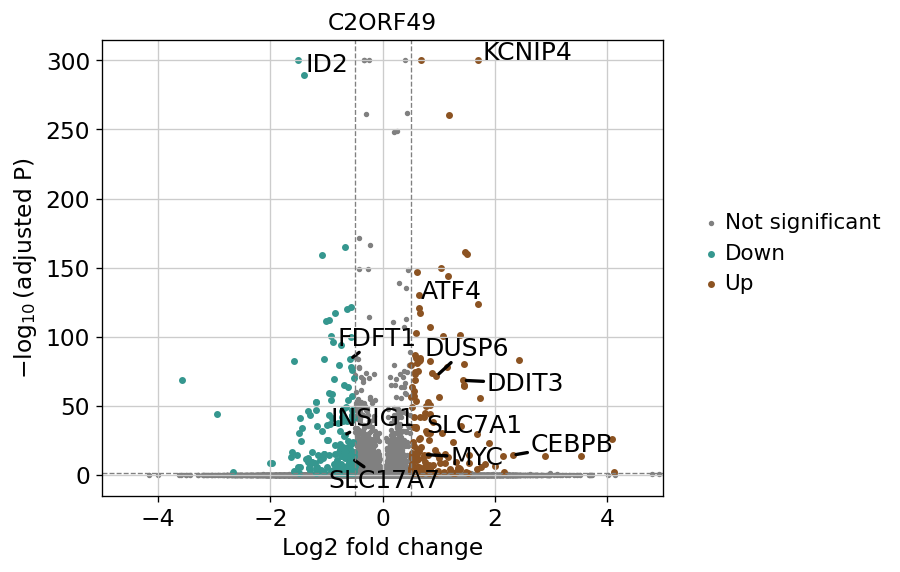

In [64]:
import numpy as np
import matplotlib.pyplot as plt
from adjustText import adjust_text

# --------------------------------------------------
# Data
# --------------------------------------------------

df = cluster_de_genes["C2ORF49"].copy()
df = df.set_index("names", drop=False)

xplot = "logfoldchanges"
xcutoff = 0.5
pcutoff = 0.05
pctcutoff = 0.05

# Volcano y-axis
df["-log10_padj"] = -np.log10(df["pvals_adj"].clip(lower=1e-300))
ycutoff = -np.log10(pcutoff)

# --------------------------------------------------
# Define significant genes
# --------------------------------------------------

down = df[
    (df[xplot] <= -xcutoff) &
    (df["pvals_adj"] < pcutoff)
]
print (f"down: {down.shape}")

up = df[
    (df[xplot] >= xcutoff) &
    (df["pvals_adj"] < pcutoff) #&
    #(df["pct_nz_group"] > pctcutoff)
]
print (f"up: {up.shape}")

# --------------------------------------------------
# Plot
# --------------------------------------------------

plt.figure(figsize=(6, 5))

plt.scatter(
    df[xplot],
    df["-log10_padj"],
    s=5,
    label="Not significant",
    color="grey"
)

plt.scatter(
    down[xplot],
    down["-log10_padj"],
    s=10,
    label="Down",
    color="#35978f"
)

plt.scatter(
    up[xplot],
    up["-log10_padj"],
    s=10,
    label="Up",
    color="#8c5322"
)

plt.xlim(-5, 5)

# --------------------------------------------------
# Label strongest DE genes
# e.g. top 10 up + top 10 down by adjusted p-value
# --------------------------------------------------

#up_label = up.nlargest(10, "logfoldchanges")
#down_label = down.nsmallest(10, "logfoldchanges")

texts = []

genes_to_label = [
    "ATF4", "DDIT3", "MYC", "DUSP6", "CEBPB",
    "SLC7A1", "INSIG1", "FDFT1", "SLC17A7",
    "ID2","KCNIP4",
]

# Label requested upregulated genes
for gene, r in up.loc[up.index.isin(genes_to_label)].iterrows():
    texts.append(
        plt.text(
            r[xplot],
            r["-log10_padj"],
            gene,
            fontsize=15,
            color='black'#"#8c5322"
        )
    )

# Label requested downregulated genes
for gene, r in down.loc[down.index.isin(genes_to_label)].iterrows():
    texts.append(
        plt.text(
            r[xplot],
            r["-log10_padj"],
            gene,
            fontsize=15,
            color='black'#"#35978f"
        )
    )

adjust_text(
    texts,
    arrowprops=dict(
        arrowstyle="-",
        color="black",
        lw=2
    )
)

# --------------------------------------------------
# Cutoffs
# --------------------------------------------------

plt.axvline(
    -xcutoff,
    color="grey",
    linestyle="--",
    linewidth=0.8
)

plt.axvline(
    xcutoff,
    color="grey",
    linestyle="--",
    linewidth=0.8
)

plt.axhline(
    ycutoff,
    color="grey",
    linestyle="--",
    linewidth=0.8
)

# --------------------------------------------------
# Labels
# --------------------------------------------------

plt.xlabel("Log2 fold change")
plt.ylabel(r"$-\log_{10}$(adjusted P)")
plt.title("C2ORF49")

plt.legend(
    bbox_to_anchor=(1.04, 0.4),
    loc="lower left",
    frameon=False
)

plt.savefig(
    "figures/volcano_C2ORF49.pdf",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [65]:
import pickle
with open('../array_scRNAseq/wilcoxon_arrayed_iAstrocytes.pkl', "rb") as f:
    cluster_de_genes = pickle.load(f)

down: (349, 7)
up: (688, 7)


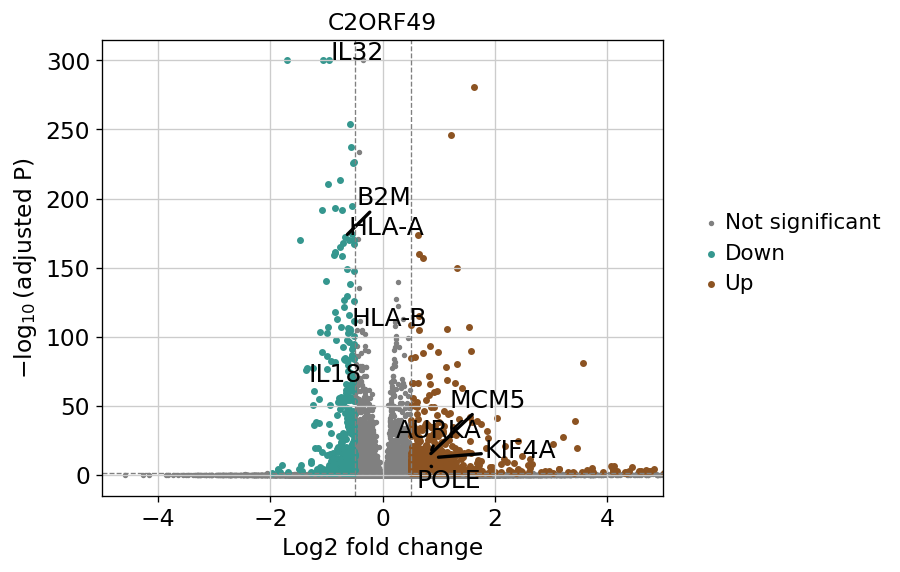

In [66]:
import numpy as np
import matplotlib.pyplot as plt
from adjustText import adjust_text

# --------------------------------------------------
# Data
# --------------------------------------------------

df = cluster_de_genes["CCDC6"].copy()
df = df.set_index("names", drop=False)

xplot = "logfoldchanges"
xcutoff = 0.5
pcutoff = 0.05
pctcutoff = 0.05

# Volcano y-axis
df["-log10_padj"] = -np.log10(df["pvals_adj"].clip(lower=1e-300))
ycutoff = -np.log10(pcutoff)

# --------------------------------------------------
# Define significant genes
# --------------------------------------------------

down = df[
    (df[xplot] <= -xcutoff) &
    (df["pvals_adj"] < pcutoff)
]
print (f"down: {down.shape}")

up = df[
    (df[xplot] >= xcutoff) &
    (df["pvals_adj"] < pcutoff) #&
    #(df["pct_nz_group"] > pctcutoff)
]
print (f"up: {up.shape}")

# --------------------------------------------------
# Plot
# --------------------------------------------------

plt.figure(figsize=(6, 5))

plt.scatter(
    df[xplot],
    df["-log10_padj"],
    s=5,
    label="Not significant",
    color="grey"
)

plt.scatter(
    down[xplot],
    down["-log10_padj"],
    s=10,
    label="Down",
    color="#35978f"
)

plt.scatter(
    up[xplot],
    up["-log10_padj"],
    s=10,
    label="Up",
    color="#8c5322"
)

plt.xlim(-5, 5)

# --------------------------------------------------
# Label strongest DE genes
# e.g. top 10 up + top 10 down by adjusted p-value
# --------------------------------------------------

#up_label = up.nlargest(10, "logfoldchanges")
#down_label = down.nsmallest(10, "logfoldchanges")

texts = []

genes_to_label = [
    "AURKA","MCM5","POLE","KIF4A",
    "IL18","IL32","B2M","HLA-A","HLA-B"
]

# Label requested upregulated genes
for gene, r in up.loc[up.index.isin(genes_to_label)].iterrows():
    texts.append(
        plt.text(
            r[xplot],
            r["-log10_padj"],
            gene,
            fontsize=15,
            color='black'#"#8c5322"
        )
    )

# Label requested downregulated genes
for gene, r in down.loc[down.index.isin(genes_to_label)].iterrows():
    texts.append(
        plt.text(
            r[xplot],
            r["-log10_padj"],
            gene,
            fontsize=15,
            color='black'#"#35978f"
        )
    )

adjust_text(
    texts,
    arrowprops=dict(
        arrowstyle="-",
        color="black",
        lw=2
    )
)

# --------------------------------------------------
# Cutoffs
# --------------------------------------------------

plt.axvline(
    -xcutoff,
    color="grey",
    linestyle="--",
    linewidth=0.8
)

plt.axvline(
    xcutoff,
    color="grey",
    linestyle="--",
    linewidth=0.8
)

plt.axhline(
    ycutoff,
    color="grey",
    linestyle="--",
    linewidth=0.8
)

# --------------------------------------------------
# Labels
# --------------------------------------------------

plt.xlabel("Log2 fold change")
plt.ylabel(r"$-\log_{10}$(adjusted P)")
plt.title("C2ORF49")

plt.legend(
    bbox_to_anchor=(1.04, 0.4),
    loc="lower left",
    frameon=False
)

plt.savefig(
    "figures/volcano_CCDC6.pdf",
    dpi=300,
    bbox_inches="tight"
)

plt.show()